# COVID-19 Global Dynamics: волны, вакцинация и смертность по странам

Итоговый мини-проект по дисциплине «Programming for Data Analysis and Database»
(тема 10, Cluster 2 «Exploratory Analytics, Time Series & Dashboards»).

- Astana IT University, образовательная программа Big Data Analysis (магистратура), группа ADA-2602M
- Команда: Serikov Alikhan, Mashina Veronika
- Преподаватель: Tleubayeva Arailym
- Данные: Our World in Data, COVID-19 dataset, лицензия CC BY 4.0 — файл `compact.csv` из каталога OWID
  (https://catalog.ourworldindata.org/garden/covid/latest/compact/compact.csv; репозиторий
  https://github.com/owid/covid-19-data не обновляется с 19.08.2024 и ссылается на этот файл)
- Код проекта: https://github.com/SalaFanChik/covid-global-dynamics

**Зачем этот ноутбук.** Весь анализ реализован в модулях проекта (`config.py`, `main.py`, пакет `src/`,
папка `dashboard/`). Ноутбук не повторяет их код: он по шагам вызывает те же функции, что и консольное меню
`python main.py`, показывает полученные таблицы и графики и даёт короткие пояснения. Все числа ниже читаются
из файлов результатов (`outputs/results.json`, `outputs/tables/*.csv`), которые создают сами шаги.

Порядок разделов повторяет пункты меню 1–6: данные → EDA → временные ряды и волны → прогноз →
база данных и SQL → корреляции и интерактивный график. В конце — выводы, ограничения, вклад участников
и ячейка для запуска дашборда.

**Как запустить.** Локально: из корня репозитория выполнить `jupyter lab notebooks/COVID19_Global_Dynamics.ipynb`
(библиотеки из `requirements.txt`). В Google Colab: открыть ноутбук с GitHub и выполнить ячейки сверху вниз —
первая ячейка сама клонирует репозиторий и установит библиотеки. Полный прогон шагов 1–6 занимает
от 20 секунд до нескольких минут в зависимости от компьютера, плюс скачивание файла данных (185 МБ)
при первом запуске.

## 0. Настройка окружения

Ячейка ниже делает ноутбук независимым от места запуска: находит корень проекта (текущая папка или папка
на уровень выше, если ноутбук открыт из `notebooks/`), а в Google Colab клонирует репозиторий и ставит
библиотеки. Затем подключается модуль `main` — тот же, что запускает консольное меню.

In [1]:
# Настройка окружения: ноутбук работает локально (из корня проекта или из папки notebooks/) и в Google Colab
import os
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/SalaFanChik/covid-global-dynamics.git"

if IN_COLAB:
    # в Colab клонируем репозиторий и устанавливаем библиотеки проекта
    if not os.path.exists("covid-global-dynamics"):
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    os.chdir("covid-global-dynamics")
    requirements = "requirements-colab.txt" if os.path.exists("requirements-colab.txt") else "requirements.txt"
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", requirements], check=True)
    # если pip обновил numpy или pandas, Colab попросит перезапустить среду — после этого выполните ячейку снова
    ROOT = os.getcwd()
elif os.path.exists("config.py"):
    ROOT = os.getcwd()                                               # ноутбук запущен из корня проекта
else:
    ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))     # ноутбук запущен из папки notebooks/
    if not os.path.exists(os.path.join(ROOT, "config.py")):
        raise FileNotFoundError("Не найден config.py: откройте ноутбук из корня репозитория или из папки notebooks/")

sys.path.insert(0, ROOT)
os.chdir(ROOT)

import pandas as pd
import plotly
import plotly.io as pio
from IPython.display import Image, display

import config
import main                      # шаги пайплайна: main.step_load_data(), main.step_eda(), ...
from src.utils import load_json

if not IN_COLAB:
    pio.renderers.default = "plotly_mimetype"   # компактный вывод Plotly без встроенной JS-библиотеки

# широкие таблицы должны читаться целиком
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 400)

print("Корень проекта:", ROOT)
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| plotly", plotly.__version__)

Корень проекта: /Users/alikhan/uni/covid-global-dynamics
Python 3.12.14 | pandas 3.1.1 | plotly 7.1.0


In [2]:
# Три помощника для показа результатов; сами расчёты живут в модулях src/ и вызываются через main.step_*()

def results():
    '''Свежая копия outputs/results.json — каждый шаг дописывает туда свой раздел.'''
    return load_json(config.RESULTS_JSON)


def table(name, **kwargs):
    '''Таблица результатов outputs/tables/<name>.csv.'''
    return pd.read_csv(config.TABLES_DIR / f"{name}.csv", **kwargs)


def figure(name, width=900):
    '''Готовый график outputs/figures/<name>.png (картинка встраивается в ноутбук).'''
    return Image(filename=str(config.FIGURES_DIR / f"{name}.png"), width=width)

## 1. Данные: загрузка, аудит качества и очистка

Шаг 1 (`main.step_load_data`) делает то же, что пункт 1 консольного меню:

1. `src.data_loader.download_dataset` скачивает CSV из каталога OWID во временный файл и переименовывает его
   только после проверки размера. Если интернета нет, шаг берёт сохранённый снимок очищенных данных
   `data/processed/covid_clean.parquet` (он лежит в репозитории).
2. `read_csv_in_chunks` читает файл частями по 100 000 строк (`chunksize`) и сразу уменьшает память каждого
   куска: даты → `datetime`, текст → `category`, числа → `float32` (кроме счётчиков и населения, которым
   нужна точность `float64`). Результат сохраняется в Parquet.
3. `compare_read_methods` сравнивает пять способов чтения одних и тех же данных по времени и памяти
   (требование 9): CSV «как есть», CSV с подбором типов, CSV чанками, потоковая агрегация по чанкам и Parquet.
4. `src.cleaning.audit_quality` собирает отчёт о качестве (пропуски, дубликаты ключа, отрицательные значения,
   пустые столбцы, локации без ISO-кода, согласованность `total_cases` и `new_cases`), а `clean_data` выполняет
   очистку и записывает каждое решение в журнал: что сделано, сколько строк затронуто и почему.

Главное решение очистки: пропуски в `new_cases` и `new_deaths` не заменяются нулями. NaN означает «отчёта не было»
(до первого случая или после того, как страна перестала отчитываться), а 0 — «отчёт был, случаев нет».
Агрегаты OWID (World, континенты, ЕС) остаются в данных с флагом `is_aggregate`, чтобы не попадать
в статистику по странам.

Если скачать файл не удалось и шаг взял снимок `covid_clean.parquet`, то таблицы и числа этого раздела
берутся из результатов предыдущего полного прогона, сохранённых в репозитории (`outputs/tables`,
`outputs/results.json`); остальные шаги выполняются заново на данных снимка.

In [3]:
main.step_load_data()

[16:11:00] ШАГ 1. Загрузка и подготовка данных
[16:11:00] Файл уже скачан: owid_covid_compact.csv (185.3 МБ)
[16:11:00]   чанк 1: 100,000 строк


[16:11:00]   чанк 2: 100,000 строк
[16:11:00]   чанк 3: 100,000 строк


[16:11:00]   чанк 4: 100,000 строк
[16:11:00]   чанк 5: 100,000 строк


[16:11:00]   чанк 6: 100,000 строк
[16:11:00]   чанк 7: 29,868 строк


[16:11:02] Загружено 629,868 строк за 2.311 с; память 326.3 -> 184.6 МБ, пик 389.0 МБ


[16:11:02] Сохранено: covid_raw_optimized.parquet (22.7 МБ)


... (2 outputs left out)

[16:11:09]   CSV чанками + оптимизация типов: файл 185.3 МБ, время 2.272 с, память 184.6 МБ, пик 378.2 МБ


[16:11:10]   CSV чанками, потоковые итоги по странам: файл 185.3 МБ, время 0.16 с, память 0.0 МБ, пик 4.5 МБ
[16:11:10]   Parquet (float32, category): файл 22.7 МБ, время 0.018 с, память 184.6 МБ, пик None МБ
[16:11:10] Аудит: 629,868 строк, 262 локаций, пустых столбцов 1, дубликатов 0, локаций без ISO-кода 15
[16:11:10]   удалены пустые столбцы: human_development_index: 629,868 строк


[16:11:10]   удалены локации без ISO-кода: 26,184 строк
[16:11:10]   помечены агрегаты OWID (is_aggregate=True): 19,840 строк
[16:11:10]   пропуски new_cases сохранены как NaN: 10,896 строк
[16:11:10]   пропуски new_deaths сохранены как NaN: 9,633 строк
[16:11:10]   удалены локации без данных о случаях: 5,461 строк
[16:11:10]   отрицательные new_cases обрезаны до 0: 0 строк
[16:11:10]   отрицательные new_deaths обрезаны до 0: 0 строк
[16:11:10]   сортировка по (location, date), добавлен столбец year: 598,223 строк
[16:11:10] После очистки: 598,223 строк, 241 локаций


[16:11:10] Сохранено: covid_clean.parquet (21.0 МБ)


In [4]:
# Сравнение способов чтения (требование 9): время — лучшее из двух запусков,
# память — итоговый DataFrame и пик по tracemalloc во время чтения
display(table("format_comparison"))

,способ,размер_файла_мб,время_с,итоговая_память_мб,пиковая_память_мб,примечание
0,"CSV как есть (float64, строки)",185.3,0.323,326.2,388.7,NaN
1,CSV + оптимизация типов,185.3,0.778,184.6,388.7,NaN
2,CSV чанками + оптимизация типов,185.3,2.272,184.6,378.2,все чанки остаются в памяти (нужны для анализа)
3,"CSV чанками, потоковые итоги по странам",185.3,0.160,0.0,4.5,в памяти только один чанк и таблица итогов
4,"Parquet (float32, category)",22.7,0.018,184.6,NaN,пик не измеряется tracemalloc (память выделяет Arrow)


In [5]:
# Главное из отчёта об аудите исходного файла (полный отчёт — outputs/tables/data_audit.json и data_audit.txt)
audit = load_json(config.TABLES_DIR / "data_audit.json")
print(f"Строк: {audit['строк']:,}, столбцов: {audit['столбцов']}, локаций: {audit['локаций']}, "
      f"период: {audit['период'][0]} … {audit['период'][1]}")
print(f"Дубликатов ключа (location, date): {audit['дубликаты_ключа_location_date']}")
print(f"Отрицательные значения: {audit['отрицательные_значения']}")
print(f"Доля нулей в new_cases: {audit['доля_нулей_new_cases']:.1%} (с 2023 г. отчётность недельная: "
      f"случаи публикуются одним днём, остальные дни = 0)")
print(f"Полностью пустые столбцы: {audit['полностью_пустые_столбцы']}")
print(f"Столбцов с пропусками более 50 %: {audit['столбцов_с_пропусками_более_50%']}")
print(f"Локаций без ISO-кода: {len(audit['локации_без_iso_code'])}, "
      f"локаций без единого отчёта о случаях: {len(audit['локации_без_данных_о_случаях'])}, "
      f"прекративших отчётность более года назад: {audit['локаций_прекративших_отчётность_более_года_назад']}")
print(f"Проверка total_cases.diff() == new_cases за 2020–2022: {audit['несогласованность_total_cases_и_new_cases']}")

Строк: 629,868, столбцов: 61, локаций: 262, период: 2020-01-01 … 2026-10-18
Дубликатов ключа (location, date): 0
Отрицательные значения: {'new_cases': 0, 'new_deaths': 0, 'new_vaccinations': 0, 'new_tests': 0}
Доля нулей в new_cases: 65.5% (с 2023 г. отчётность недельная: случаи публикуются одним днём, остальные дни = 0)
Полностью пустые столбцы: ['human_development_index']
Столбцов с пропусками более 50 %: 37
Локаций без ISO-кода: 15, локаций без единого отчёта о случаях: 6, прекративших отчётность более года назад: 4
Проверка total_cases.diff() == new_cases за 2020–2022: {'строк_проверено': 254409, 'расхождений': 0}


In [6]:
# Журнал очистки: каждое решение с числом затронутых строк и обоснованием
display(pd.DataFrame(load_json(config.TABLES_DIR / "cleaning_log.json")))

,шаг,затронуто_строк,обоснование
0,удалены пустые столбцы: human_development_index,629868,столбцы не содержат ни одного значения
1,удалены локации без ISO-кода,26184,"не страны и не официальные агрегаты OWID: Asia excl. China, England, England and Wales, High-income countries, Low-income countries, Lower-middle-income countries, Northern Ireland, Scotland, Summer Olympics 2020, Upper-middle-income countries, Wales, Winter Olympics 2022, World excl. China, World excl. China and South Korea, World excl. China, South Korea, Japan and Singapore"
2,помечены агрегаты OWID (is_aggregate=True),19840,"World, континенты и ЕС нужны для графиков, но не должны попадать в статистику по странам"
3,пропуски new_cases сохранены как NaN,10896,"NaN = отчёта не было (до первого случая или после прекращения отчётности), 0 = случаев не было"
4,пропуски new_deaths сохранены как NaN,9633,"NaN = отчёта не было (до первого случая или после прекращения отчётности), 0 = случаев не было"
5,удалены локации без данных о случаях,5461,"ни одного отчёта о случаях (ВОЗ не публикует данные): Cote d'Ivoire, Western Sahara, Hong Kong, Macao, Transnistria, Taiwan"
6,отрицательные new_cases обрезаны до 0,0,"отрицательные значения — это задним числом исправленная статистика, а не реальные случаи"
7,отрицательные new_deaths обрезаны до 0,0,"отрицательные значения — это задним числом исправленная статистика, а не реальные случаи"
8,"сортировка по (location, date), добавлен столбец year",598223,год нужен для фильтров дашборда и SQL-запросов


In [7]:
# Итоги шага из results.json
R = results()["1_данные"]
load = R["загрузка"]
formats = {row["способ"]: row for row in R["сравнение_форматов"]}
csv_plain = formats["CSV как есть (float64, строки)"]
parquet = formats["Parquet (float32, category)"]
streaming = formats["CSV чанками, потоковые итоги по странам"]
print(f"Файл {load['файл']}: {load['размер_файла_мб']} МБ, {load['строк']:,} строк × {load['столбцов']} столбцов, md5 {load['md5']}")
print(f"Чтение чанками: {load['чанков']} чанков по {load['размер_чанка']:,} строк за {load['время_чтения_с']} с, "
      f"пик памяти {load['пиковая_память_мб']} МБ")
print(f"Оптимизация типов: {load['память_до_оптимизации_мб']} → {load['память_после_оптимизации_мб']} МБ "
      f"(экономия {load['экономия_памяти_%']} %)")
print(f"Parquet: файл {parquet['размер_файла_мб']} МБ вместо {csv_plain['размер_файла_мб']} МБ, "
      f"чтение {parquet['время_с']} с вместо {csv_plain['время_с']} с у CSV")
print(f"Потоковая обработка чанками: пик памяти {streaming['пиковая_память_мб']} МБ — "
      f"так можно обработать файл, который не помещается в память")
print(f"После очистки: {R['после_очистки']['строк']:,} строк, {R['после_очистки']['локаций']} локаций "
      f"(страны и 8 агрегатов OWID с флагом is_aggregate)")

Файл owid_covid_compact.csv: 185.3 МБ, 629,868 строк × 61 столбцов, md5 0af7a57f919d603b77986a0f3af7679c
Чтение чанками: 7 чанков по 100,000 строк за 2.311 с, пик памяти 389.0 МБ
Оптимизация типов: 326.3 → 184.6 МБ (экономия 43.4 %)
Parquet: файл 22.7 МБ вместо 185.3 МБ, чтение 0.018 с вместо 0.323 с у CSV
Потоковая обработка чанками: пик памяти 4.5 МБ — так можно обработать файл, который не помещается в память
После очистки: 598,223 строк, 241 локаций (страны и 8 агрегатов OWID с флагом is_aggregate)


**Что показывает шаг.** Подбор типов почти вдвое уменьшает память таблицы, а Parquet хранит те же данные в файле
в несколько раз меньшего размера и читается на порядок быстрее CSV. Чтение чанками само по себе медленнее
(куски нужно склеивать), но именно оно позволяет работать с файлом, который не помещается в память: вариант
с потоковыми итогами по странам держит в памяти только один чанк. Поэтому CSV читается чанками один раз,
а все дальнейшие шаги работают с Parquet. Удалённые при очистке локации — это не страны (части Великобритании,
группы по доходу, Олимпиады, «мир без Китая») и территории без единого отчёта о случаях.

## 2. Разведочный анализ (EDA)

Шаг 2 (`main.step_eda`, модуль `src/eda.py`) отвечает на четыре вопроса задачи кластера:

- типы признаков — `feature_types` делит столбцы на числовые, категориальные, дату и логические;
- описательная статистика — `describe_numeric` по ключевым показателям только для стран (агрегаты исключены);
- пропуски — `missing_report` считает число и долю пропусков по каждому столбцу;
- выбросы — `detect_outliers_iqr` применяет правило IQR (`[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`) к накопленной
  смертности на миллион жителей внутри каждого континента; boxplot показывает те же границы графически.

Здесь же строится сводная таблица `country_summary` (одна строка на страну: итоги пандемии и постоянные
характеристики страны), которую дальше используют корреляционный анализ и SQL-запросы.

In [8]:
main.step_eda()

[16:11:10] ШАГ 2. EDA
[16:11:10] EDA: 233 стран, выбросов по смертности 15 (Peru, Georgia, Armenia, Guam, Tunisia...)


[16:11:11]   график сохранён: deaths_boxplot_by_continent.png


In [9]:
# Типы признаков очищенной таблицы
from src import eda

for kind, columns in eda.feature_types(main.get_clean_df()).items():
    shown = ", ".join(columns) if len(columns) <= 8 else ", ".join(columns[:8]) + ", …"
    print(f"{kind}: {len(columns)} — {shown}")

числовые: 57 — total_cases, new_cases, new_cases_smoothed, total_cases_per_million, new_cases_per_million, new_cases_smoothed_per_million, total_deaths, new_deaths, …
категориальные: 3 — location, iso_code, continent
дата: 1 — date
логические: 1 — is_aggregate


In [10]:
# Описательная статистика ключевых показателей (только страны)
display(table("eda_describe"))

,показатель,count,mean,std,min,25%,50%,75%,max,доля_пропусков
0,new_cases,572948.0,1360.448,29479.615,0.000,0.000,0.000,9.000,6966046.000,0.009
1,new_deaths,574211.0,12.406,127.052,0.000,0.000,0.000,0.000,44047.000,0.007
2,new_cases_per_million,572948.0,84.779,925.818,0.000,0.000,0.000,1.208,230762.547,0.009
3,new_deaths_per_million,574211.0,0.518,3.956,0.000,0.000,0.000,0.000,608.643,0.007
4,total_cases_per_million,577840.0,144651.016,184776.219,0.000,3995.644,59256.871,237191.266,769806.812,0.001
5,total_deaths_per_million,577840.0,976.723,1223.808,0.000,47.769,433.444,1572.429,6604.037,0.001
6,reproduction_rate,181710.0,0.909,0.401,-0.069,0.714,0.948,1.137,5.872,0.686
7,stringency_index,198376.0,42.811,25.019,0.000,22.220,42.750,62.040,100.000,0.657
8,people_fully_vaccinated_per_hundred,58827.0,46.245,29.649,0.000,17.673,52.894,73.432,110.188,0.898
9,positive_rate,101560.0,10.418,13.123,0.000,1.610,5.488,14.268,94.505,0.824


In [11]:
# Пропуски: 15 самых разреженных столбцов
missing = table("eda_missing")
print(f"Столбцов с пропусками: {int((missing['пропусков'] > 0).sum())} из {len(missing)}")
display(missing.head(15))

Столбцов с пропусками: 57 из 62


,столбец,пропусков,доля
0,weekly_icu_admissions,587230,0.9816
1,weekly_icu_admissions_per_million,587230,0.9816
2,excess_mortality_cumulative_per_million,584475,0.9770
3,excess_mortality_cumulative_absolute,584475,0.9770
4,excess_mortality_cumulative,584475,0.9770
5,excess_mortality,584475,0.9770
6,weekly_hosp_admissions_per_million,578557,0.9671
7,weekly_hosp_admissions,578557,0.9671
8,icu_patients_per_million,563398,0.9418
9,icu_patients,563398,0.9418


,группа,наблюдений,нижняя_граница,верхняя_граница,выбросов
0,Africa,56,-398.9,752.9,10
1,Asia,47,-1045.8,2171.8,2
2,Europe,51,-1339.3,6642.5,0
3,North America,41,-916.0,3910.3,0
4,Oceania,24,-1088.2,2069.8,2
5,South America,14,-236.3,4823.3,1


,location,continent,total_deaths_per_million
0,Peru,South America,6604.03660
1,Georgia,Asia,4519.62740
2,Armenia,Asia,3049.41550
3,Guam,Oceania,2536.42700
4,Tunisia,Africa,2427.77300
5,French Polynesia,Oceania,2318.21600
6,South Africa,Africa,1644.71950
7,Namibia,Africa,1422.30870
8,Seychelles,Africa,1370.15760
9,Eswatini,Africa,1170.70750


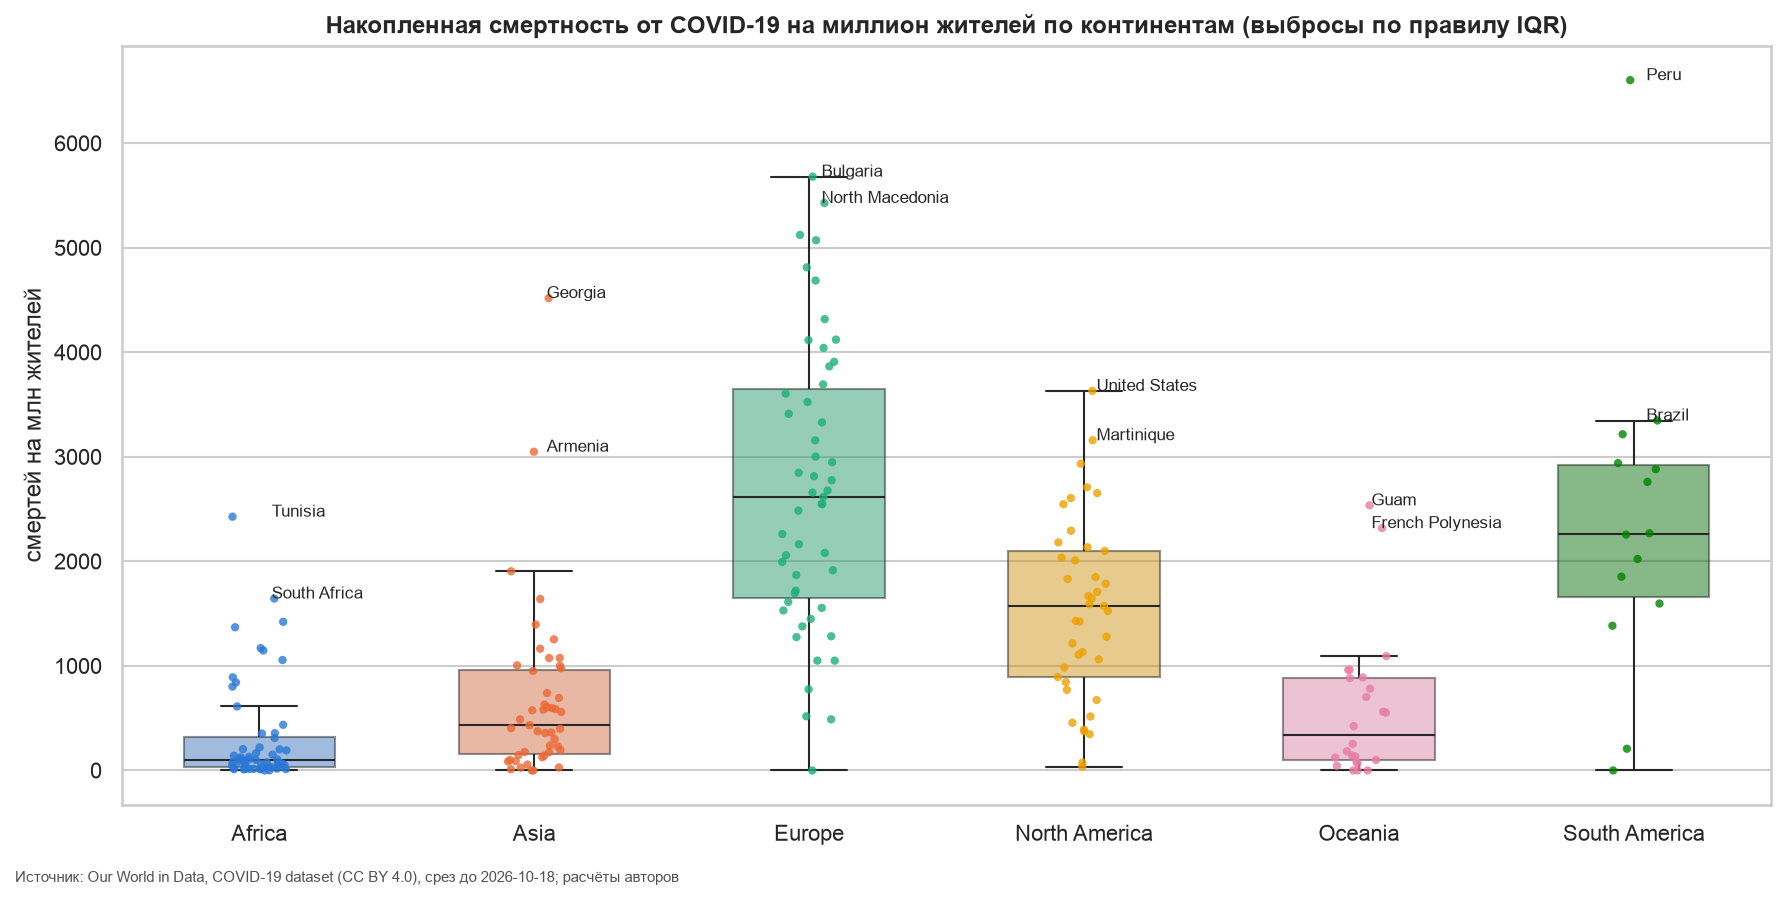

In [12]:
# Выбросы по правилу IQR внутри континентов: границы по группам и сами страны-выбросы
display(table("eda_outliers_summary"))
display(table("eda_outliers_deaths").sort_values("total_deaths_per_million", ascending=False).reset_index(drop=True))
display(figure("deaths_boxplot_by_continent"))

In [13]:
R = results()["2_eda"]
print(f"Типы признаков: {R['типы_признаков']}")
print(f"Стран в сводке: {R['стран_в_сводке']}; столбцов с пропусками: {R['столбцов_с_пропусками']}")
print(f"Выбросов по смертности на млн (IQR внутри континента): {R['выбросов_смертность_на_млн']}; "
      f"самые сильные: {', '.join(R['страны_выбросы'][:5])}")

Типы признаков: {'числовые': 57, 'категориальные': 3, 'дата': 1, 'логические': 1}
Стран в сводке: 233; столбцов с пропусками: 57
Выбросов по смертности на млн (IQR внутри континента): 15; самые сильные: Peru, Georgia, Armenia, Guam, Tunisia


**Что показывает шаг.** Самые разреженные столбцы — госпитализации, реанимации и избыточная смертность:
их публикует небольшая часть стран, поэтому в базе данных эти блоки хранятся отдельными таблицами (только
непустые строки). Распределения показателей сильно скошены: медианы дневных случаев и смертей равны нулю,
а максимумы — миллионы случаев и десятки тысяч смертей за день, поэтому дальше используются недельные суммы
и ранговые корреляции. Выбросы
по смертности — страны, которые сильно выделяются внутри своего континента (Перу в Южной Америке, Грузия
и Армения в Азии, страны юга Африки); сравнение между континентами здесь осложняется разной полнотой учёта.

## 3. Временные ряды и детекция волн

Шаг 3 (`main.step_timeseries_and_waves`, модули `src/timeseries.py` и `src/waves.py`) — центральная часть темы.

**Частота анализа — неделя.** `make_weekly_table` переводит дневные данные в недельные суммы (`Grouper`
по неделям с понедельника по воскресенье, то же, что `resample('W')`) и считает показатели на миллион жителей.
Неделя без единого отчёта остаётся пропуском, а не нулём. Почему неделя: с 2023 г. ВОЗ публикует данные раз
в неделю, а в дневных данных 2020–2022 гг. есть сильный эффект дня недели — он показан ниже на декомпозиции
дневного ряда США с периодом 7 дней (`decompose_series`, `weekday_effect`).

**Скользящее среднее.** `rolling_mean` считает 7-дневное среднее, которое сравнивается с готовым столбцом OWID
`new_cases_smoothed` (таблица `rolling_mean_kazakhstan`) — проверка правильности расчёта.

**Сезонная декомпозиция.** Для мирового недельного ряда применяется мультипликативная модель с периодом
52 недели; сила сезонности считается по формуле Хиндмана (Hyndman; функция `seasonality_strength`). Ряд короче четырёх лет,
поэтому результат носит описательный характер.

**Волны — два метода (требование 9: сравнение подходов с baseline).**
- *Порог (baseline)*: волна — отрезок не короче 4 недель, где сглаженный ряд выше медианы ненулевых недельных
  значений страны; разрывы до 2 недель склеиваются.
- *Пики (`scipy.signal.find_peaks`)*: пики ищутся на логарифме 3-недельного центрированного скользящего среднего.
  Пик считается волной, если заболеваемость до и после него менялась не менее чем в 2 раза (prominence ≥ ln 2),
  пики разделены не менее чем 8 неделями, а сам пик не ниже 50 случаев на миллион в неделю. Граница между
  соседними пиками — впадина между ними, поэтому волны не пересекаются и случаи не считаются дважды
  (`check_wave_coverage`). Смерти относятся к волне со сдвигом 2 недели; по ним считается летальность волны (CFR).

Качество методов измеряется долей найденных эталонных пиков — известных из публикаций ВОЗ/OWID месяцев пиков
для пяти стран (`config.REFERENCE_PEAKS`), согласованностью пиков двух методов (индекс Жаккара) и долей
неправдоподобно длинных волн (дольше года). Чувствительность метода пиков к главному параметру показана
в таблице `wave_sensitivity`.

In [14]:
main.step_timeseries_and_waves()

[16:11:11] ШАГ 3. Временные ряды и волны
[16:11:11] Недельная таблица: 85,555 строк, 241 локаций
[16:11:11]   resample vs Grouper (Казахстан): совпадают 355 из 355 недель


[16:11:11]   график сохранён: seasonal_decomposition_us_daily.png
[16:11:11]   график сохранён: weekday_effect.png
[16:11:11]   график сохранён: seasonal_decomposition_world.png


[16:11:11] Метод «threshold»: 816 волн в 229 странах за 0.156 с
[16:11:11] Метод «peaks»: 1429 волн в 225 странах за 0.158 с
[16:11:11] Метод «peaks»: 26 волн в 5 странах за 0.004 с
[16:11:11] Метод «peaks»: 20 волн в 5 странах за 0.003 с
[16:11:11] Метод «peaks»: 20 волн в 5 странах за 0.003 с


[16:11:11] Метод «peaks»: 15 волн в 5 странах за 0.003 с


[16:11:12]   график сохранён: waves_small_multiples.png
[16:11:12]   график сохранён: wave_methods_comparison.png


,пн,вт,ср,чт,пт,сб,вс
"отклонение от среднего уровня, %",-30.6,-37.5,4.7,4.2,32.4,13.3,13.6


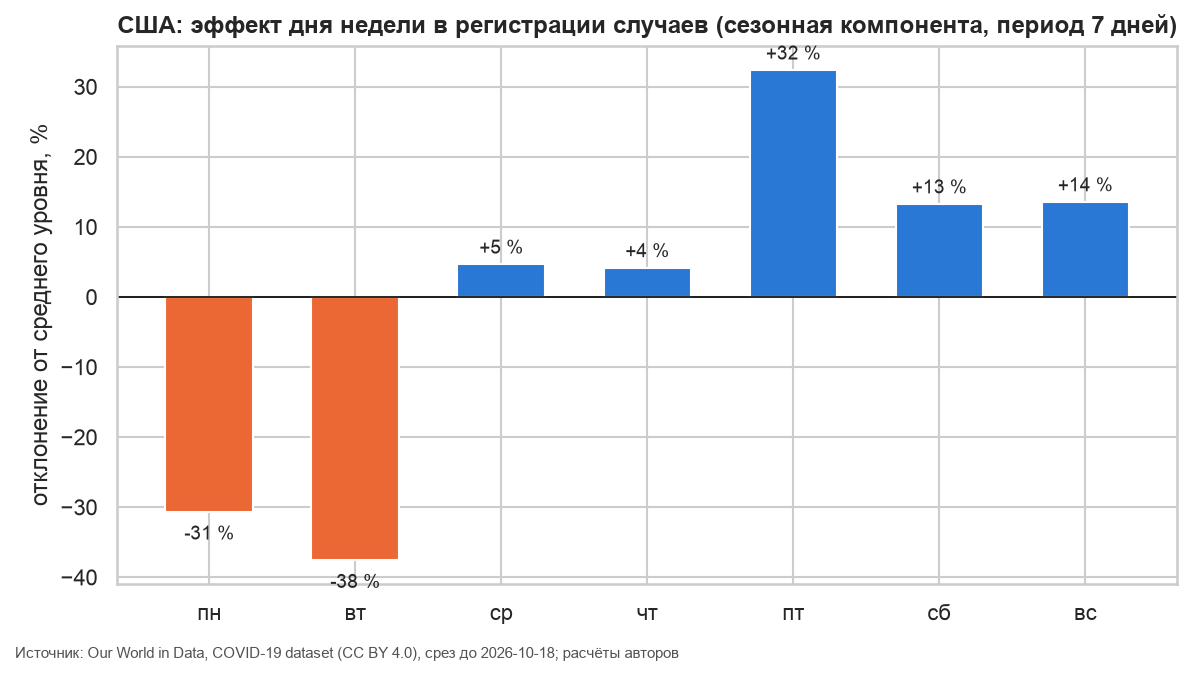

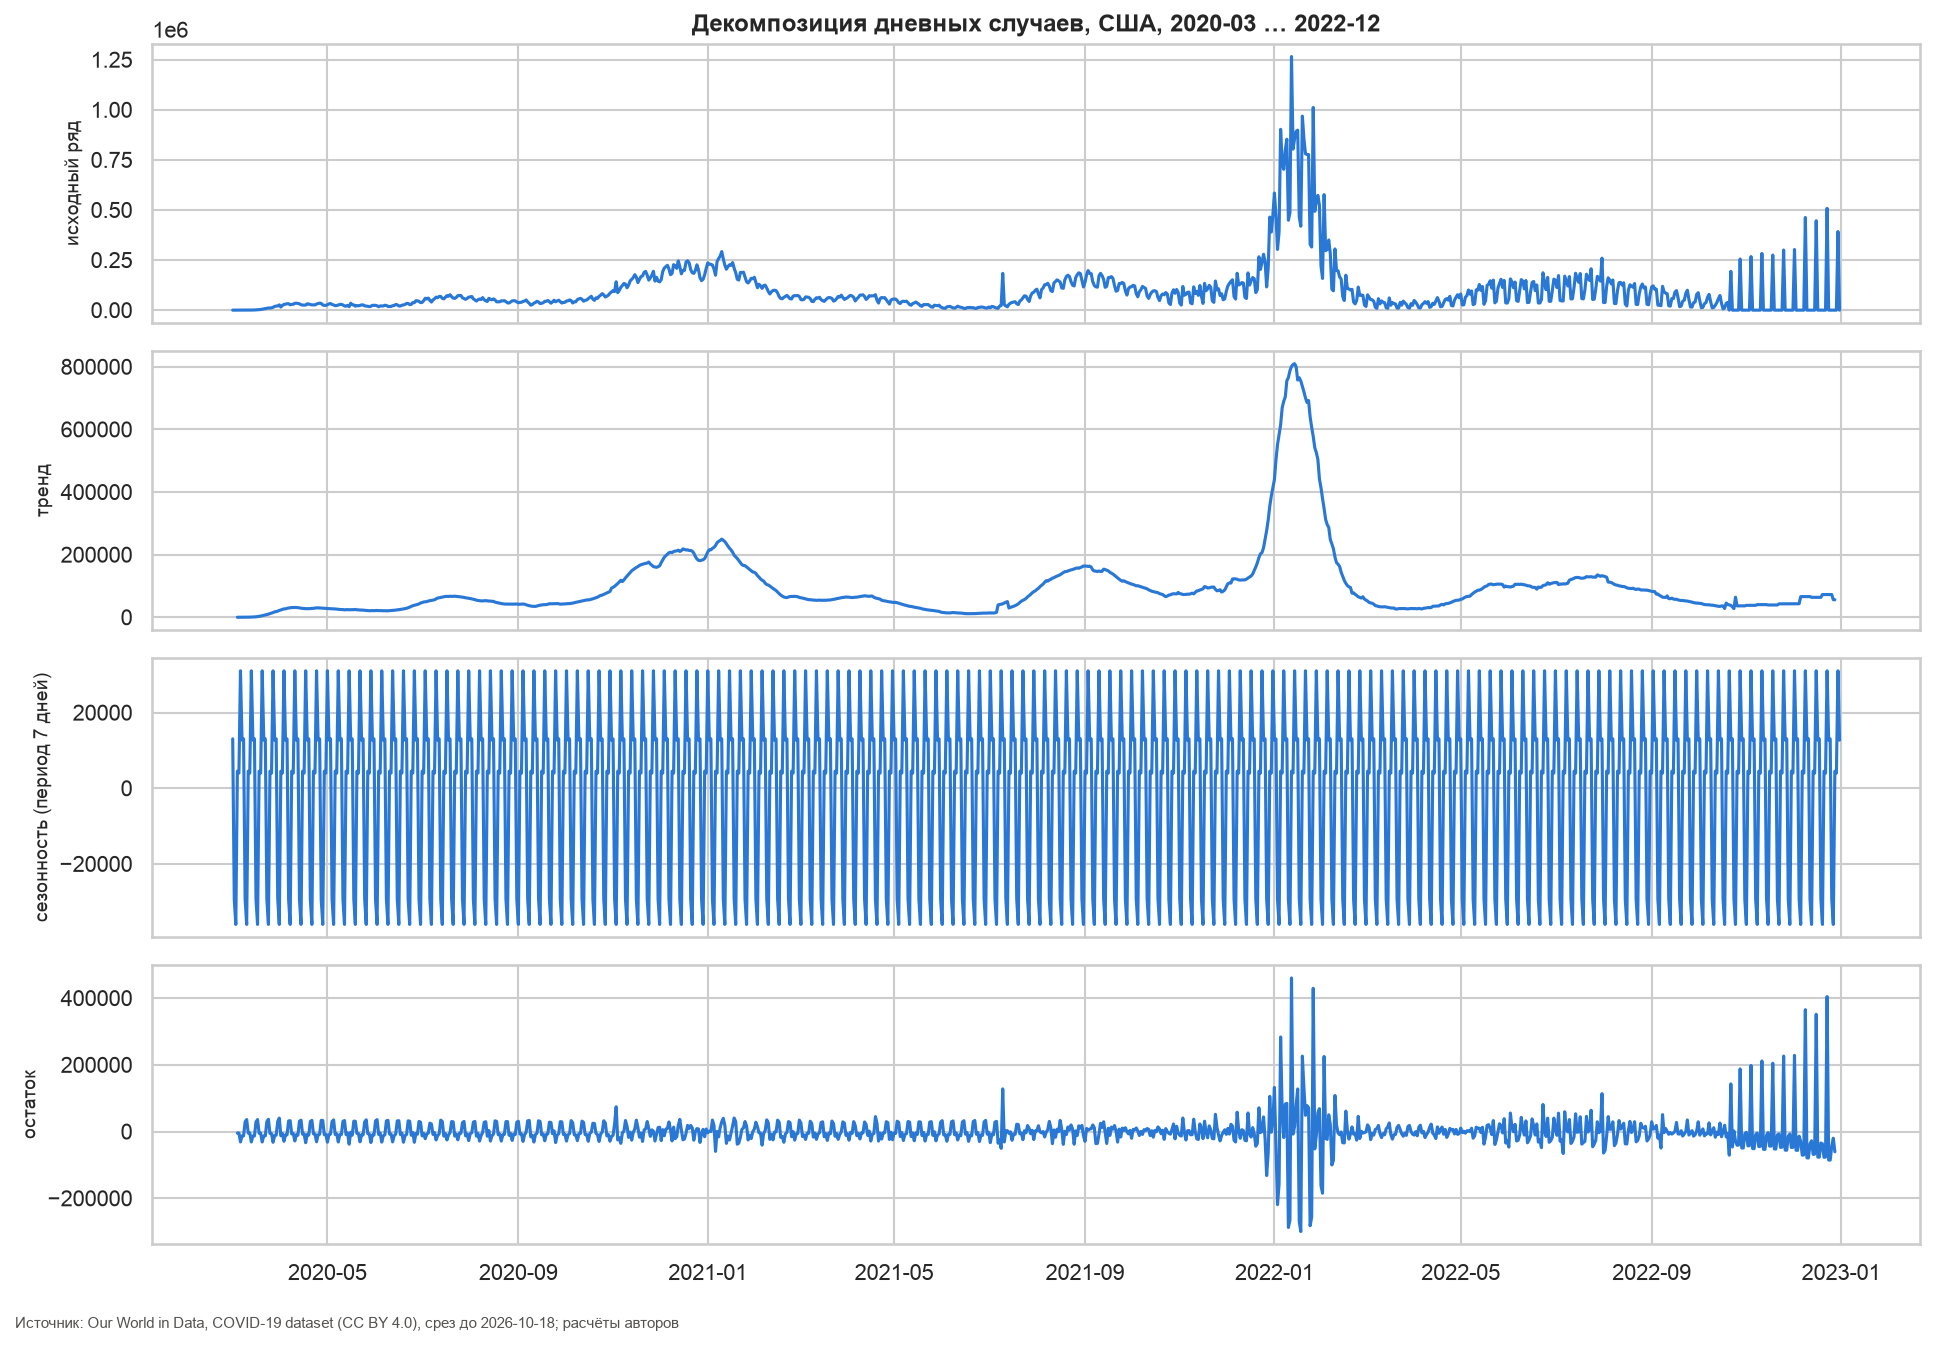

In [15]:
# Эффект дня недели в дневном ряду США: сезонная компонента декомпозиции с периодом 7 дней
R = results()["3_ряды_и_волны"]
display(pd.DataFrame([R["эффект_дня_недели_сша_%"]], index=["отклонение от среднего уровня, %"]))
display(figure("weekday_effect", width=700))
display(figure("seasonal_decomposition_us_daily"))

In [16]:
# Наше 7-дневное скользящее среднее против готового столбца OWID (Казахстан, лето 2021)
rolling = table("rolling_mean_kazakhstan", parse_dates=["date"])
display(rolling.head(7))
difference = (rolling["rolling_7d_наш"] - rolling["new_cases_smoothed_owid"]).abs().max()
print(f"Максимальное расхождение за июль–август 2021 г. (число дней: {len(rolling)}): {difference:.4f} случая в день — "
      f"разница только в округлении столбца OWID")

,date,new_cases,rolling_7d_наш,new_cases_smoothed_owid
0,2021-07-01,2524.0,1815.857143,1815.8572
1,2021-07-02,2666.0,1979.142857,1979.1428
2,2021-07-03,2852.0,2131.714286,2131.7144
3,2021-07-04,3073.0,2319.714286,2319.7144
4,2021-07-05,3113.0,2521.428571,2521.4285
5,2021-07-06,2627.0,2707.714286,2707.7144
6,2021-07-07,2738.0,2799.000000,2799.0000


Максимальное расхождение за июль–август 2021 г. (число дней: 62): 0.0001 случая в день — разница только в округлении столбца OWID


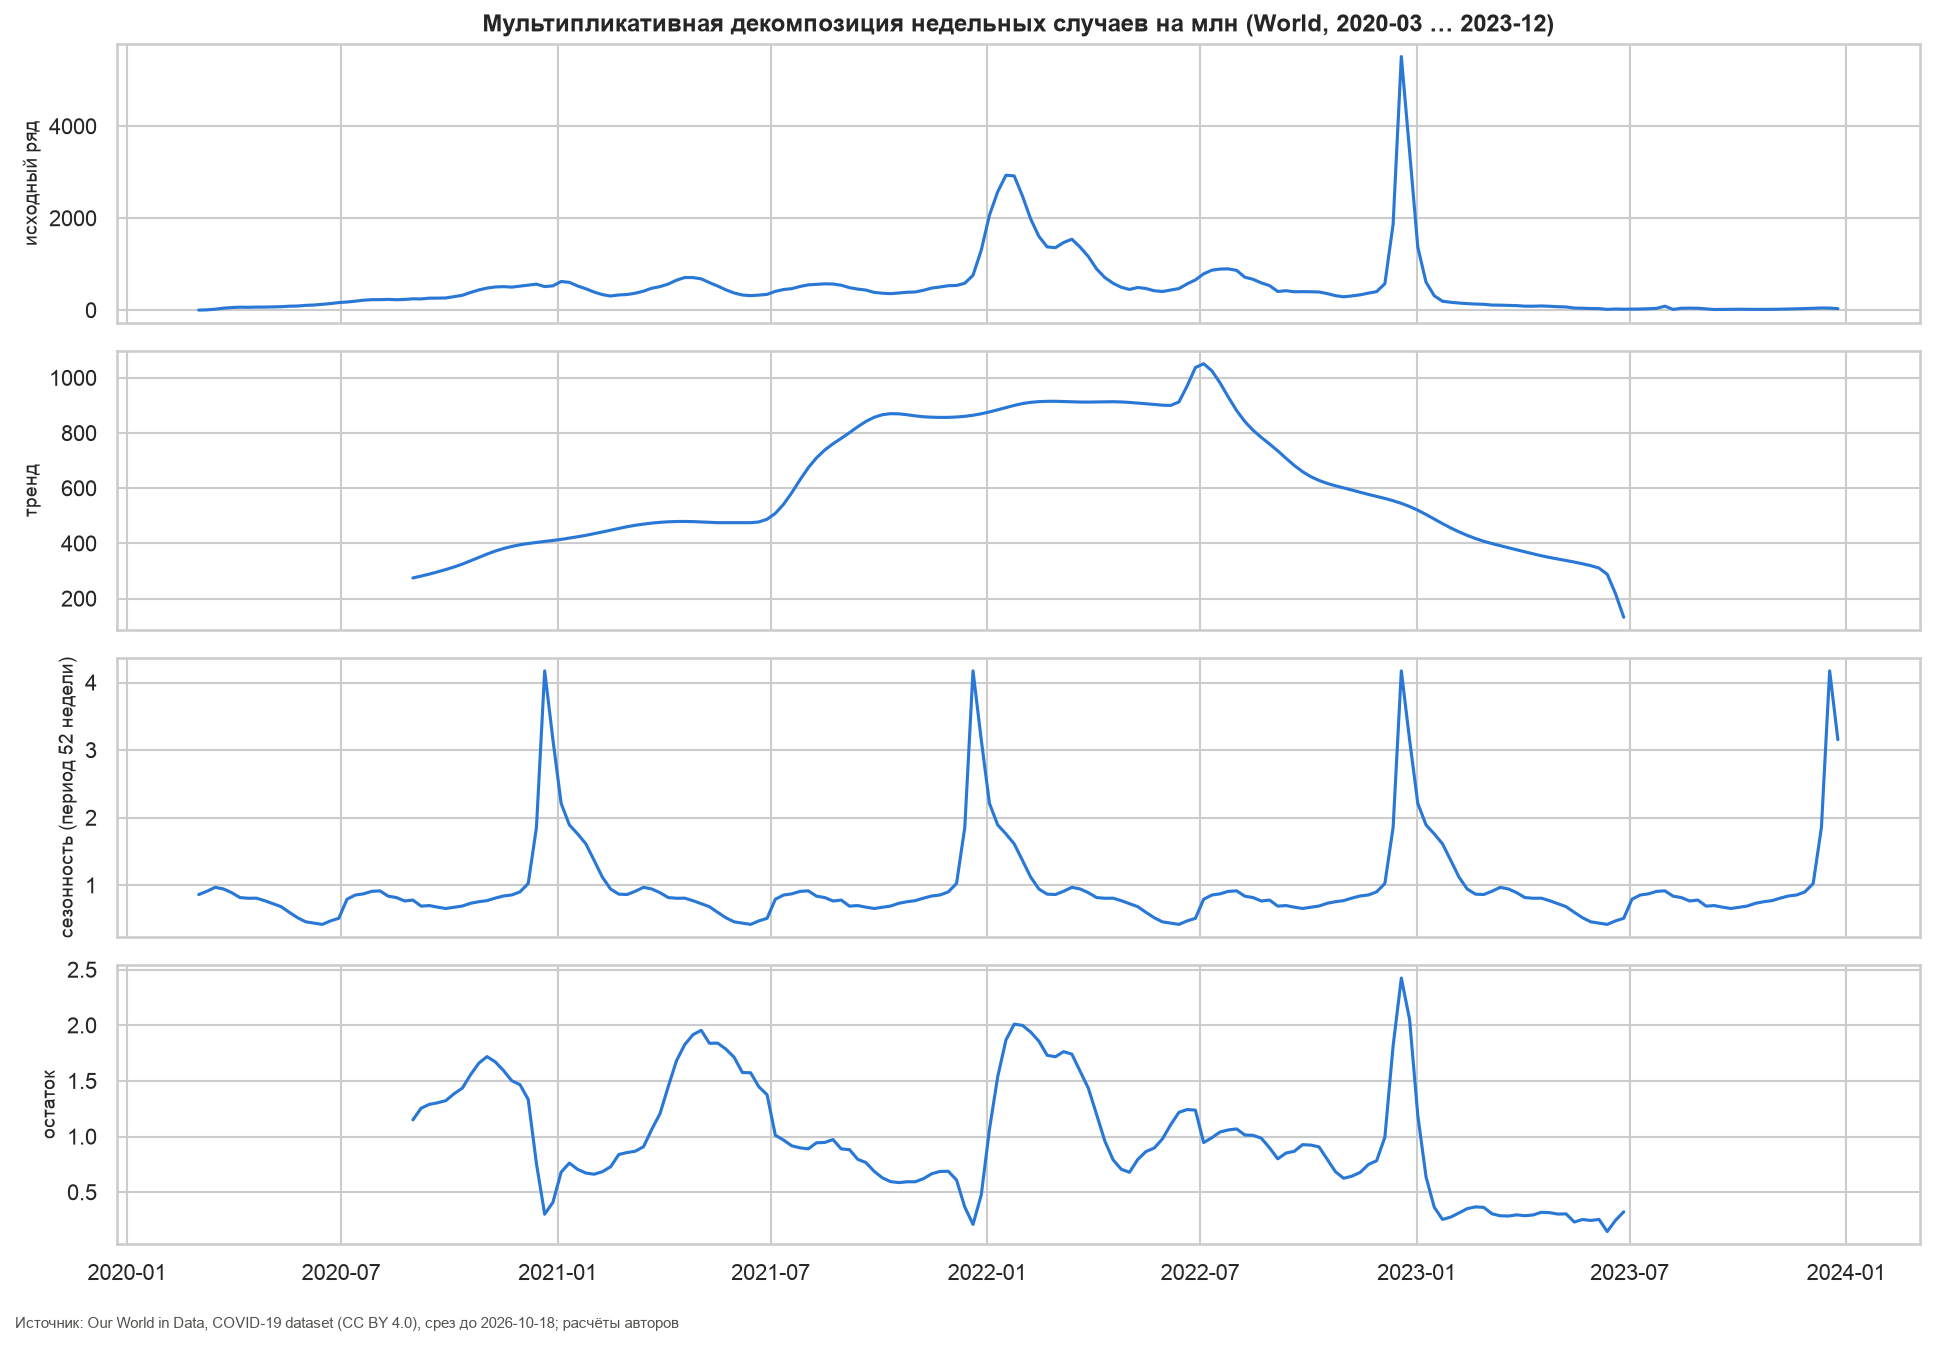

Сила годовой сезонности (Хиндман, 0 — нет, 1 — сильная): 0.628; ряд содержит меньше четырёх полных циклов, поэтому это только описание, а не доказательство сезонности


In [17]:
# Годовая сезонность мирового недельного ряда: мультипликативная декомпозиция, период 52 недели
display(figure("seasonal_decomposition_world"))
print(f"Сила годовой сезонности (Хиндман, 0 — нет, 1 — сильная): {R['сила_годовой_сезонности_world']}; "
      f"ряд содержит меньше четырёх полных циклов, поэтому это только описание, а не доказательство сезонности")

,wave_no,start_date,peak_date,end_date,peak_weekly_cases_per_million,cfr_pct,size
0,1,2020-05-11,2020-07-06,2020-09-28,703.4,1.54,малая
1,2,2020-10-05,2021-04-19,2021-05-31,959.8,1.77,малая
2,3,2021-06-07,2021-08-02,2021-12-13,2729.8,1.73,средняя
3,4,2021-12-20,2022-01-17,2022-05-16,3870.6,0.24,средняя
4,5,2022-05-23,2022-07-25,2022-10-17,842.2,0.04,малая
5,6,2022-10-24,2022-12-19,2023-05-01,76.9,0.11,малая


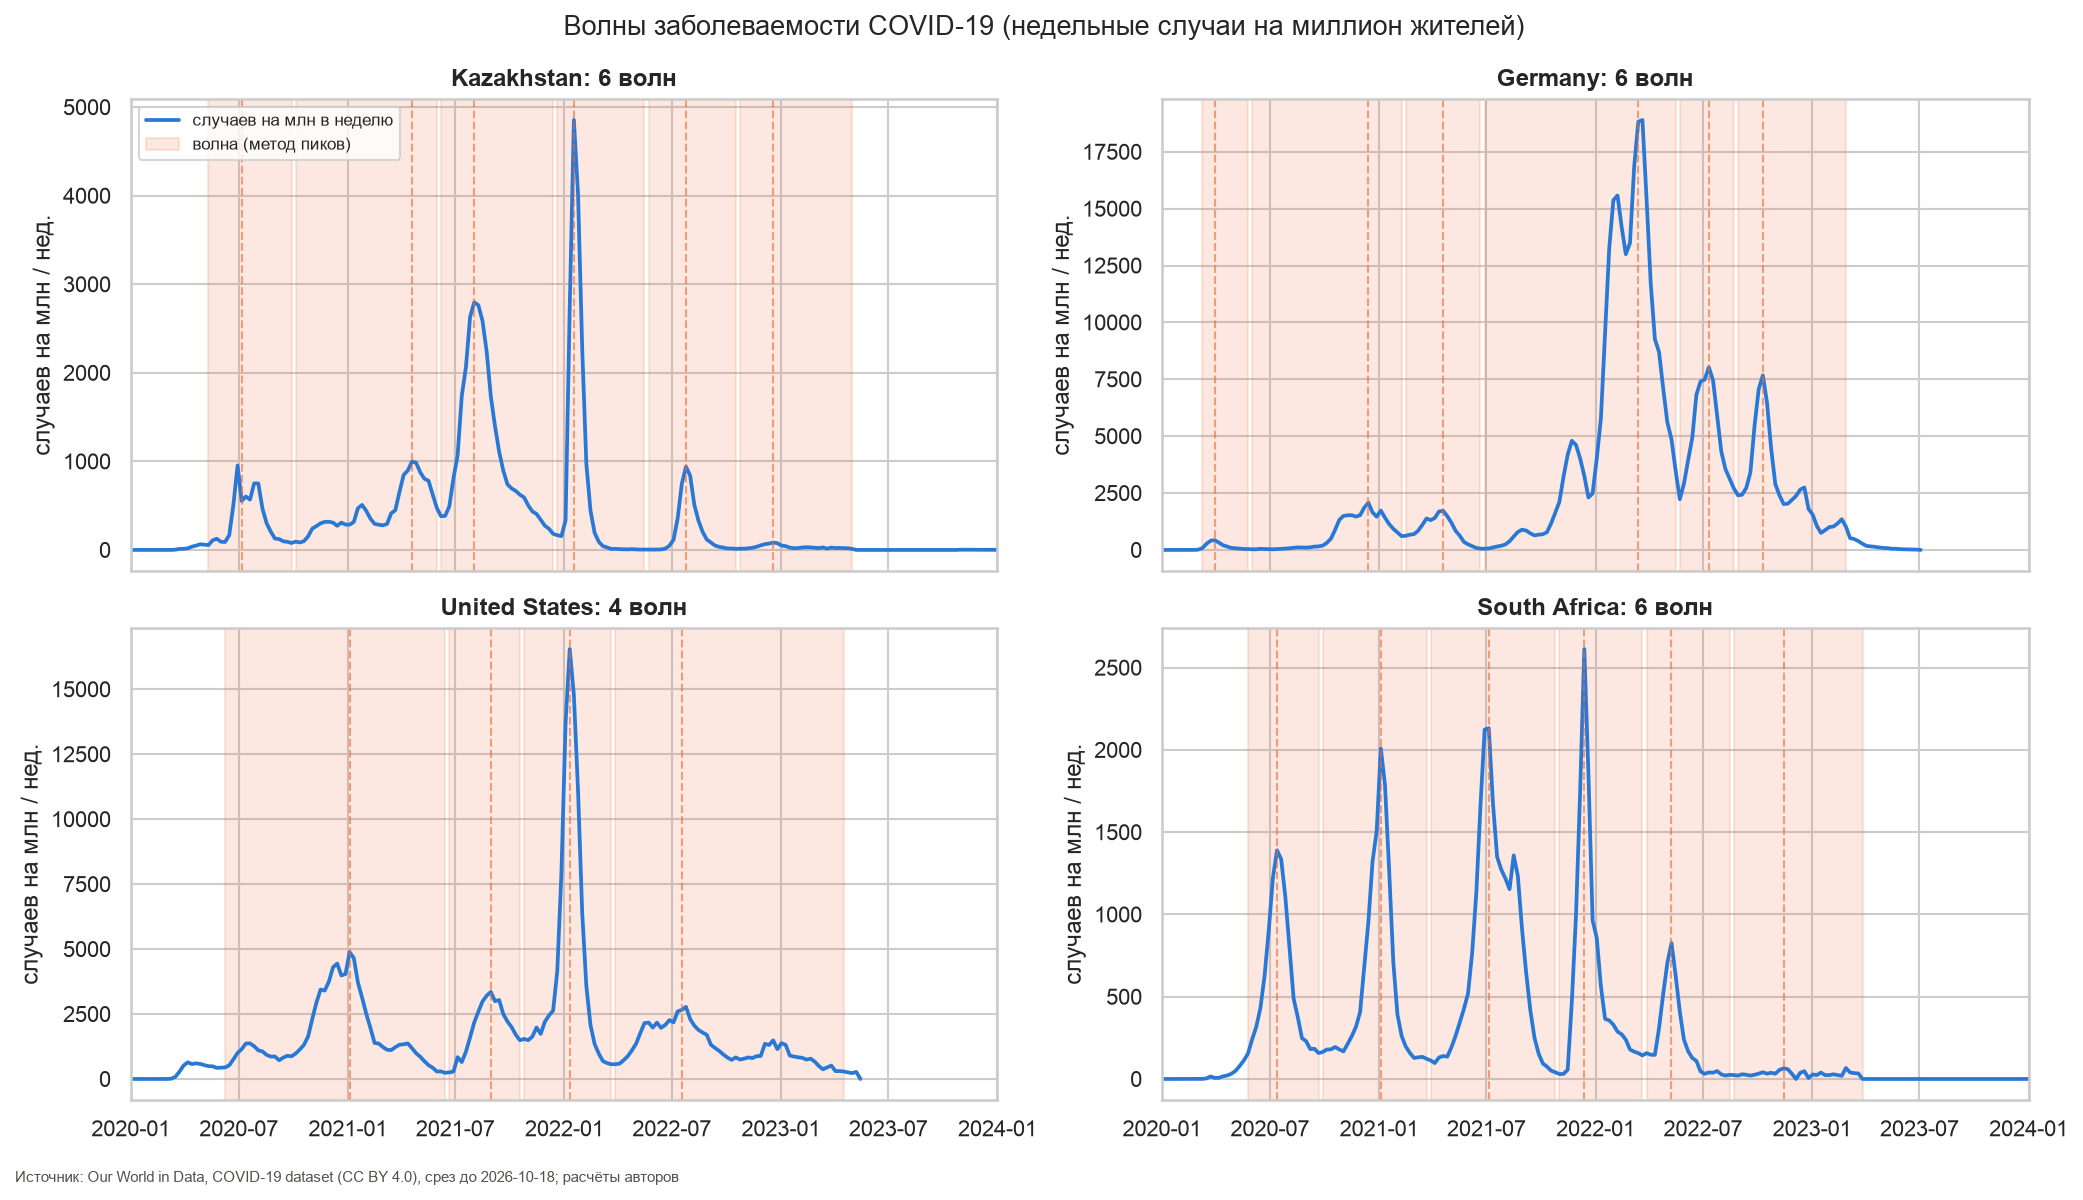

In [18]:
# Волны Казахстана методом пиков (из results.json) и график волн для четырёх стран
display(pd.DataFrame(R["волны_казахстан"]))
display(figure("waves_small_multiples"))

,метод,волн_всего,стран,найдено_эталонных_пиков_%,волн_на_страну,медиана_длительности_нед,доля_волн_длиннее_года_%,медиана_жаккара,доля_стран_жаккар_≥0.5_%,время_с
0,порог (baseline),581,156,73.7,3.72,15.0,8.8,0.5,57.1,0.156
1,пики (find_peaks),835,151,100.0,5.53,25.0,5.9,0.5,57.1,0.158


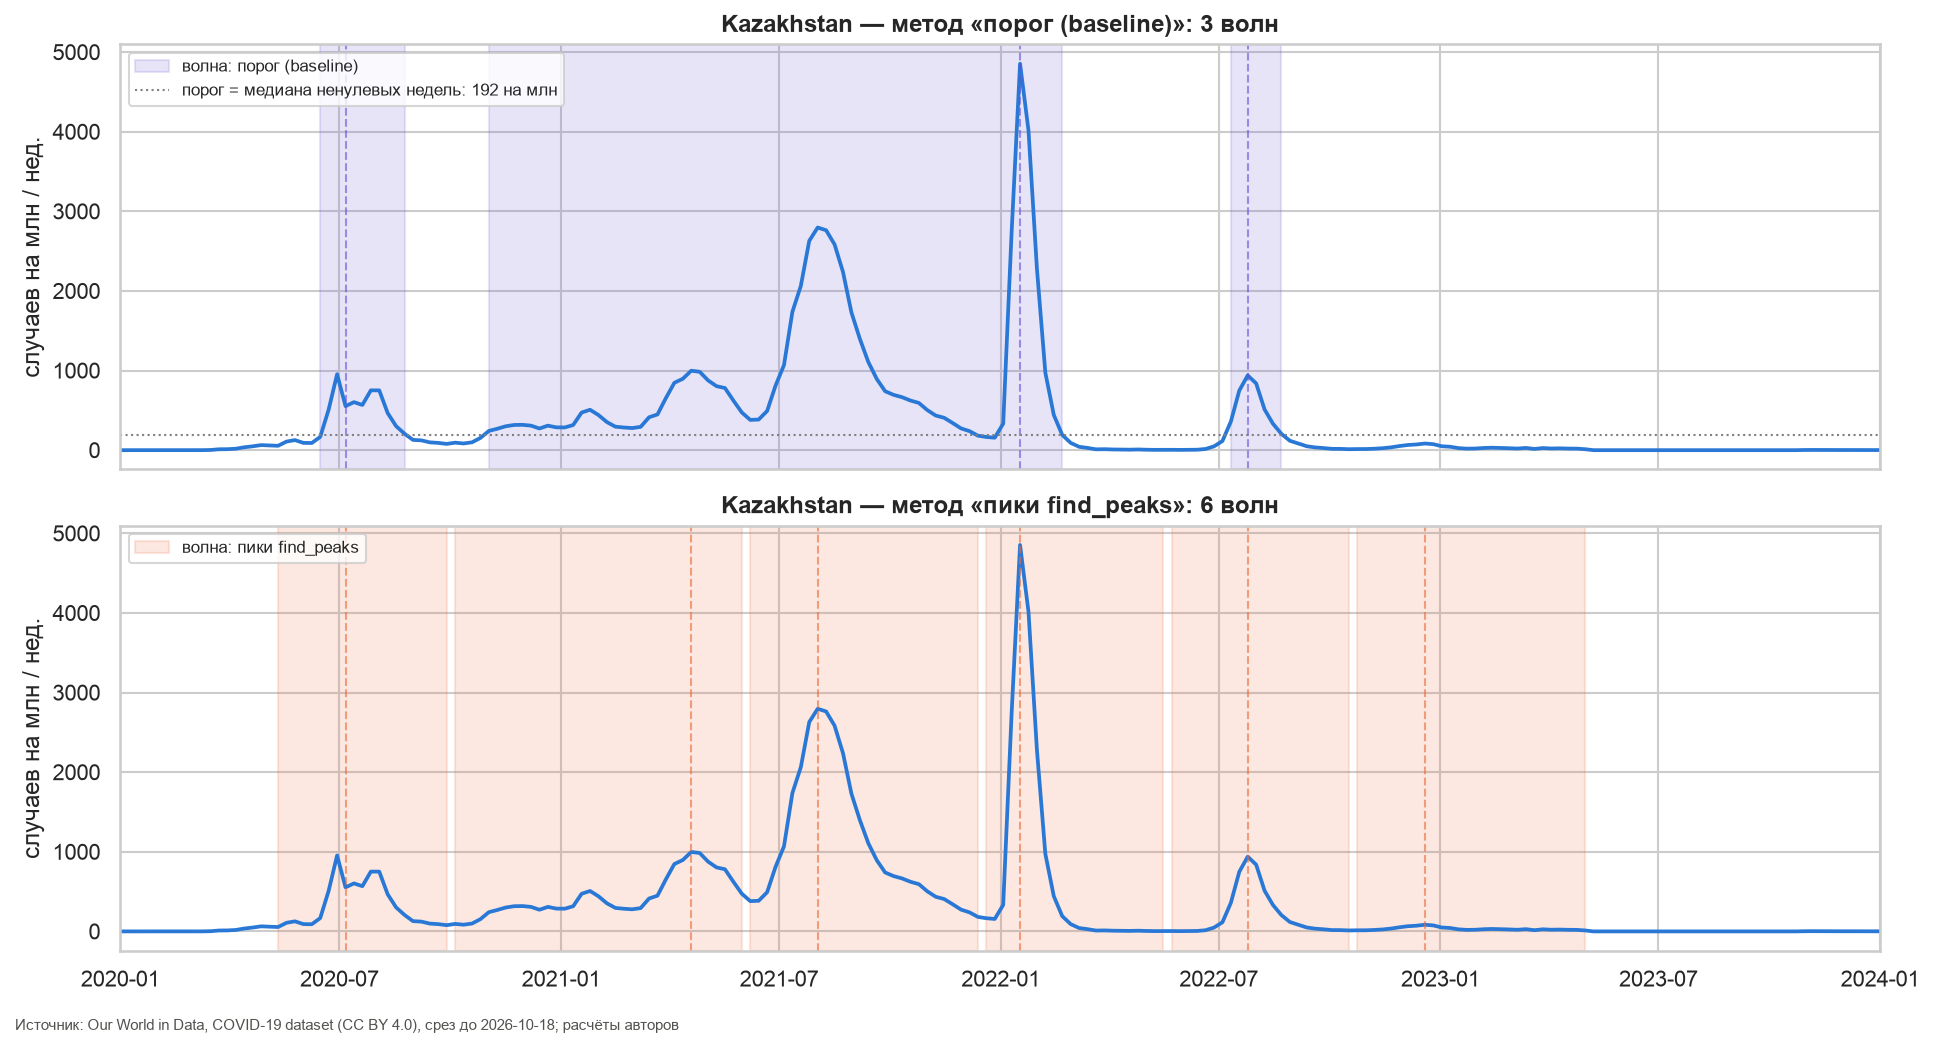

In [19]:
# Сравнение двух методов на странах с населением ≥ 1 млн; ниже — оба метода на одной стране
display(table("wave_methods_comparison"))
display(figure("wave_methods_comparison"))

In [20]:
# Метрика качества: сколько эталонных пиков (месяцы из публикаций ВОЗ/OWID) нашёл метод пиков
from src.waves import reference_recall

recall, by_country = reference_recall(main.get_waves()["peaks"])     # волны шага 3: из кэша STATE или из CSV
display(by_country)
print(f"Найдено эталонных пиков (± 4 недели): {recall} %")

,location,эталонных_пиков,найдено,всего_волн_методом
0,Kazakhstan,5,5,6
1,South Africa,5,5,6
2,Germany,3,3,6
3,United States,3,3,4
4,India,3,3,4


Найдено эталонных пиков (± 4 недели): 100.0 %


In [21]:
# Чувствительность метода пиков к параметру prominence: число волн у пяти стран
display(table("wave_sensitivity"))

,множитель,prominence,рост_и_спад_не_менее_раз,Kazakhstan,Germany,United States,India,South Africa
0,1.0,0.693,2.0,6,6,4,4,6
1,1.5,1.040,2.8,5,3,3,4,5
2,2.0,1.386,4.0,5,3,3,4,5
3,3.0,2.079,8.0,4,3,2,3,3


In [22]:
R = results()["3_ряды_и_волны"]
effect = R["эффект_дня_недели_сша_%"]
print(f"Эффект дня недели (США): пн {effect['пн']:+.1f} %, вт {effect['вт']:+.1f} %, пт {effect['пт']:+.1f} % к среднему уровню")
kz = R["волны_казахстан"]
print(f"Казахстан, метод пиков: {len(kz)} волн; пики {', '.join(w['peak_date'] for w in kz)}; "
      f"CFR по волнам, %: {', '.join(str(w['cfr_pct']) for w in kz)}")
print("Сравнение методов (страны ≥ 1 млн жителей):")
for row in R["сравнение_методов"]:
    print(f"  {row['метод']}: {row['волн_всего']} волн в {row['стран']} странах ({row['волн_на_страну']} на страну), "
          f"медиана длительности {row['медиана_длительности_нед']:.0f} нед., найдено эталонных пиков "
          f"{row['найдено_эталонных_пиков_%']} %, волн длиннее года {row['доля_волн_длиннее_года_%']} %, "
          f"время {row['время_с']} с")
print(f"Проверка непересечения волн: максимальная доля случаев страны внутри волн = {R['доля_случаев_в_волнах_макс']} (не больше 1)")

Эффект дня недели (США): пн -30.6 %, вт -37.5 %, пт +32.4 % к среднему уровню
Казахстан, метод пиков: 6 волн; пики 2020-07-06, 2021-04-19, 2021-08-02, 2022-01-17, 2022-07-25, 2022-12-19; CFR по волнам, %: 1.54, 1.77, 1.73, 0.24, 0.04, 0.11
Сравнение методов (страны ≥ 1 млн жителей):
  порог (baseline): 581 волн в 156 странах (3.72 на страну), медиана длительности 15 нед., найдено эталонных пиков 73.7 %, волн длиннее года 8.8 %, время 0.156 с
  пики (find_peaks): 835 волн в 151 странах (5.53 на страну), медиана длительности 25 нед., найдено эталонных пиков 100.0 %, волн длиннее года 5.9 %, время 0.158 с
Проверка непересечения волн: максимальная доля случаев страны внутри волн = 1.0 (не больше 1)


**Что показывает шаг.** Регистрация случаев проседает в начале недели и навёрстывается к пятнице, поэтому
дневные ряды нельзя сравнивать напрямую, а недельная сумма этого эффекта не содержит. Наше 7-дневное среднее
совпадает со столбцом OWID — расчёт верен. Метод пиков находит все эталонные пики известных волн, тогда как
пороговый baseline пропускает часть из них и даёт больше неправдоподобно длинных «волн»: если ряд долго
держится выше медианы, несколько волн склеиваются в одну. У Казахстана метод пиков выделяет волны лета 2020 г.,
весны и лета 2021 г. (Дельта), зимы 2022 г. (Омикрон) и два меньших подъёма 2022 г.; летальность волн падает
от первых волн к омикронным. Чем больший перепад вокруг пика требуется (prominence), тем меньше волн —
выбранное значение ln 2 («рост и спад не менее чем вдвое») даёт число волн, согласующееся с публикациями.

## 4. Прогноз недельной заболеваемости и сравнение с baseline

Шаг 4 (`main.step_forecast`, модуль `src/forecasting.py`) сравнивает четыре простые модели по MAE на недельных
случаях на миллион жителей для десяти стран проекта (`config.FOCUS_COUNTRIES`) и мира:

- `naive` (baseline) — прогноз равен последнему известному значению;
- `seasonal_naive` (baseline) — значение 52 недели назад;
- `moving_average` — среднее последних 4 недель;
- `linear_regression` — линейная регрессия на 4 лагах, которая переобучается в каждой точке.

Протокол — скользящее начало (rolling origin): для каждой недели периода оценки модель видит только данные
до этой недели включительно и прогнозирует на 1 и на 4 недели вперёд (прямой многошаговый прогноз). Так исключена
утечка данных из будущего. Период оценки задан в `config.FORECAST_START … FORECAST_END` — пока все выбранные
страны отчитывались регулярно. Метрика — MAE; дополнительно считаются отношение MAE к naive (меньше 1 — модель
лучше baseline) и число «побед» — для скольких рядов модель оказалась лучшей.

In [23]:
main.step_forecast()

[16:11:12] ШАГ 4. Прогноз и сравнение с baseline


[16:11:12]   Kazakhstan: лучшая модель linear_regression (h=1, MAE=130.67)
[16:11:12]   Russia: лучшая модель linear_regression (h=1, MAE=147.09)


[16:11:12]   Germany: лучшая модель linear_regression (h=1, MAE=404.74)


[16:11:12]   United States: лучшая модель linear_regression (h=1, MAE=363.83)


[16:11:12]   Brazil: лучшая модель linear_regression (h=1, MAE=223.08)
[16:11:12]   India: лучшая модель linear_regression (h=1, MAE=34.17)


[16:11:12]   Italy: лучшая модель linear_regression (h=1, MAE=521.22)


[16:11:12]   Japan: лучшая модель naive (h=1, MAE=474.28)


[16:11:12]   South Africa: лучшая модель linear_regression (h=1, MAE=107.68)
[16:11:12]   United Kingdom: лучшая модель naive (h=1, MAE=578.53)


[16:11:13]   World: лучшая модель naive (h=1, MAE=156.59)


[16:11:13]   linear_regression, горизонт 1 нед.: MAE=301.908, лучше naive на 10 %, побед 8
[16:11:13]   linear_regression, горизонт 4 нед.: MAE=1180.458, хуже naive на 15 %, побед 2
[16:11:13]   moving_average, горизонт 1 нед.: MAE=690.914, хуже naive на 103 %, побед 0
[16:11:13]   moving_average, горизонт 4 нед.: MAE=1196.302, хуже naive на 15 %, побед 0
[16:11:13]   naive, горизонт 1 нед.: MAE=339.786, baseline, побед 3
[16:11:13]   naive, горизонт 4 нед.: MAE=1050.388, baseline, побед 9
[16:11:13]   seasonal_naive, горизонт 1 нед.: MAE=1931.595, baseline, побед 0
[16:11:13]   seasonal_naive, горизонт 4 нед.: MAE=1925.105, baseline, побед 0


[16:11:13]   график сохранён: forecast_comparison.png


,model,horizon_weeks,mae_mean,mae_vs_naive_mean,wins,seconds_total
0,linear_regression,1,301.908,0.895,8,0.585
1,naive,1,339.786,1.000,3,0.023
2,moving_average,1,690.914,2.027,0,0.044
3,seasonal_naive,1,1931.595,5.381,0,0.022
4,naive,4,1050.388,1.000,9,0.023
5,linear_regression,4,1180.458,1.153,2,0.585
6,moving_average,4,1196.302,1.148,0,0.044
7,seasonal_naive,4,1925.105,1.737,0,0.022


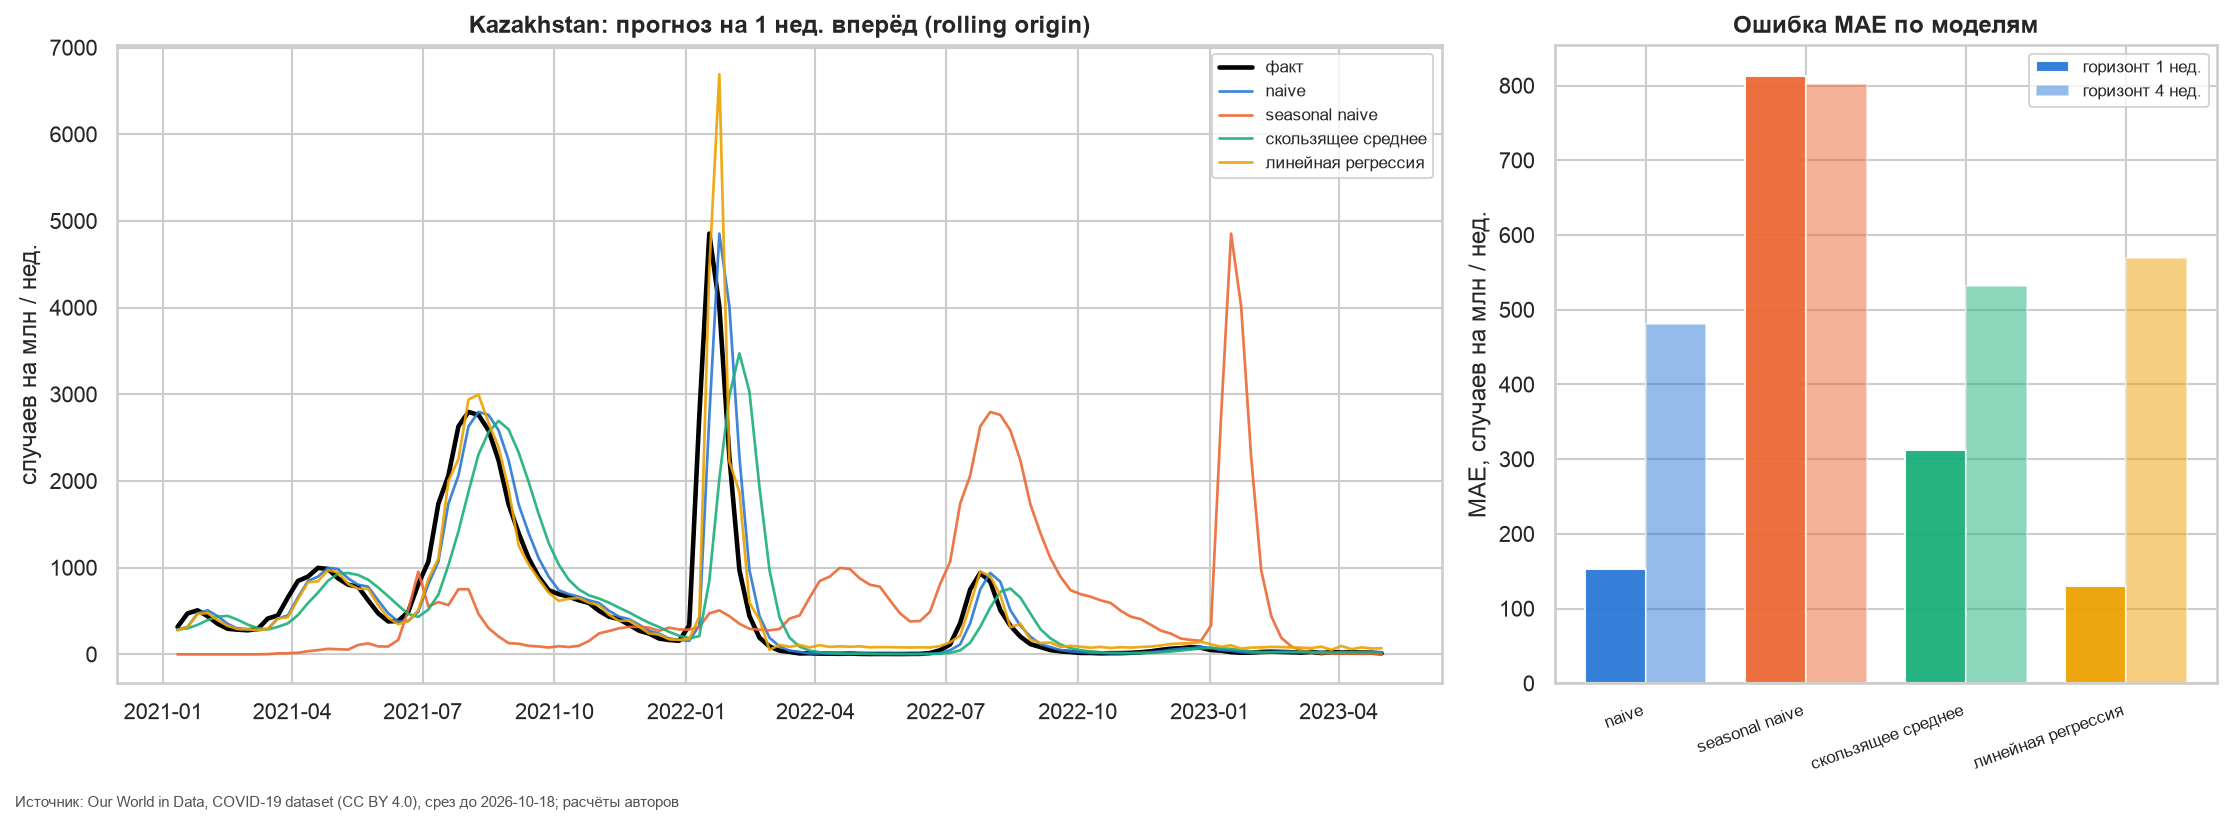

In [24]:
# Сводка по моделям: средний MAE по 11 рядам, отношение к naive, число побед, суммарное время
display(table("forecast_summary").sort_values(["horizon_weeks", "mae_mean"]).reset_index(drop=True))
display(figure("forecast_comparison", width=1000))

In [25]:
# Метрики для Казахстана и ошибка naive по годам: год Омикрона (2022) определяет величину ошибки
metrics = table("forecast_metrics")
display(metrics[metrics["location"] == "Kazakhstan"].reset_index(drop=True))
mae_by_year = table("forecast_mae_by_year")
display(mae_by_year[mae_by_year["model"] == "naive"]
        .groupby(["horizon_weeks", "year"])["mae"].mean().round(1).unstack("year")
        .rename_axis(index="горизонт, нед.", columns="год целевой недели"))

,location,model,horizon_weeks,n_forecasts,mae,seconds,mae_vs_naive,is_baseline
0,Kazakhstan,naive,1,121,152.69,0.003,1.000,True
1,Kazakhstan,naive,4,121,480.34,0.003,1.000,True
2,Kazakhstan,seasonal_naive,1,121,813.35,0.002,5.327,True
3,Kazakhstan,seasonal_naive,4,121,802.74,0.002,1.671,True
4,Kazakhstan,moving_average,1,121,312.91,0.004,2.049,False
5,Kazakhstan,moving_average,4,121,532.17,0.004,1.108,False
6,Kazakhstan,linear_regression,1,121,130.67,0.061,0.856,False
7,Kazakhstan,linear_regression,4,121,569.48,0.061,1.186,False


год целевой недели,2021,2022,2023
"горизонт, нед.",,,
1,209.0,544.0,120.5
4,572.6,1760.2,379.9


In [26]:
R = results()["4_прогноз"]
print(f"Период оценки: {R['период_оценки'][0]} … {R['период_оценки'][1]}; горизонты {config.FORECAST_HORIZONS} нед.; "
      f"рядов: {len(config.FOCUS_COUNTRIES) + 1} (10 стран и World)")
summary = pd.DataFrame(R["сводка"])
for horizon, part in summary.groupby("horizon_weeks"):
    best = part.loc[part["mae_mean"].idxmin()]
    print(f"Горизонт {horizon} нед.: лучшая модель {best['model']} — MAE {best['mae_mean']}, "
          f"{best['mae_vs_naive_mean']} от naive, побед {best['wins']} из {int(part['wins'].sum())}")
print("Выводы шага:")
for line in R["выводы"]:
    print("  " + line)

Период оценки: 2021-01-01 … 2023-04-30; горизонты [1, 4] нед.; рядов: 11 (10 стран и World)
Горизонт 1 нед.: лучшая модель linear_regression — MAE 301.908, 0.895 от naive, побед 8 из 11
Горизонт 4 нед.: лучшая модель naive — MAE 1050.388, 1.0 от naive, побед 9 из 11
Выводы шага:
  linear_regression, горизонт 1 нед.: MAE=301.908, лучше naive на 10 %, побед 8
  linear_regression, горизонт 4 нед.: MAE=1180.458, хуже naive на 15 %, побед 2
  moving_average, горизонт 1 нед.: MAE=690.914, хуже naive на 103 %, побед 0
  moving_average, горизонт 4 нед.: MAE=1196.302, хуже naive на 15 %, побед 0
  naive, горизонт 1 нед.: MAE=339.786, baseline, побед 3
  naive, горизонт 4 нед.: MAE=1050.388, baseline, побед 9
  seasonal_naive, горизонт 1 нед.: MAE=1931.595, baseline, побед 0
  seasonal_naive, горизонт 4 нед.: MAE=1925.105, baseline, побед 0


**Что показывает шаг.** На неделю вперёд линейная регрессия на лагах немного точнее naive и выигрывает у него
в большинстве рядов; на месяц вперёд в среднем ничто не обгоняет naive — пандемическая кривая слишком резко меняет
направление. Скользящее среднее запаздывает на подъёмах и спадах, а seasonal naive хуже всех: у пандемии нет
устойчивой годовой сезонности, волны прошлого года не повторяются в те же недели. Величину ошибки определяет
2022 год (волна Омикрона) — это видно по таблице MAE по годам.

## 5. База данных SQLite и SQL-запросы

Шаг 5 (`main.step_database`, модули `src/database.py` и `src/sql_queries.py`) сохраняет очищенные данные
в SQLite `data/covid.db` и выполняет каталог аналитических запросов.

Схема нормализована (3НФ): справочники `continents` и `locations` (постоянные характеристики стран плюс даты
первого и последнего отчёта), таблица фактов `daily_stats`, отдельные разреженные блоки `vaccinations`,
`hospitalizations`, `testing`, `excess_mortality` (только непустые строки), витрина `weekly_stats`, которая
строится SQL-запросом из `daily_stats` и сверяется с pandas, а также таблицы результатов анализа `waves`
и `forecast_results`. Внешние ключи включены (`PRAGMA foreign_keys = ON`); созданы четыре индекса: по дате
в `daily_stats` и `weekly_stats`, по стране в `waves` и по континенту в `locations`. ER-диаграмма `docs/erd.png`
строится скриптом `scripts/make_erd.py` по реальной схеме базы.

Словарь `QUERIES` содержит запросы с JOIN нескольких таблиц, GROUP BY/HAVING, подзапросами, CTE и оконными
функциями (RANK, LAG, ROW_NUMBER, SUM/AVG OVER, COUNT OVER). Все результаты выгружаются в pandas
(`pd.read_sql_query`), сохраняются в `outputs/tables/sql_<имя>.csv` и используются в графиках
(`top15_deaths_per_million`, `cfr_by_wave_year`), в корреляционном анализе и в дашборде. Сравнение Pandas vs SQL
(требование 9) делает один и тот же недельный агрегат двумя способами и сверяет результаты.

In [27]:
main.step_database()

[16:11:13] ШАГ 5. База данных и SQL


[16:11:15]   daily_stats: 598,223 строк
[16:11:15]   vaccinations: 76,748 строк
[16:11:15]   hospitalizations: 41,543 строк


[16:11:15]   testing: 104,052 строк
[16:11:15]   excess_mortality: 13,748 строк


[16:11:15]   waves: 2,245 строк, forecast_results: 88 строк
[16:11:15] База собрана за 2.739 с, размер 91.9 МБ
[16:11:16]   top15_deaths_per_million: 15 строк за 0.197 с


[16:11:16]   cases_by_continent_year: 22 строк за 0.252 с
[16:11:16]   world_monthly_change: 82 строк за 0.001 с
[16:11:16]   rank_within_continent: 18 строк за 0.049 с
[16:11:16]   rolling_average_kazakhstan: 62 строк за 0.001 с
[16:11:16]   vaccination_vs_deaths_2022: 155 строк за 0.032 с
[16:11:16]   waves_per_country: 151 строк за 0.002 с
[16:11:16]   waves_by_continent: 5 строк за 0.0 с
[16:11:16]   cfr_by_wave_year: 7 строк за 0.0 с
[16:11:16]   countries_above_world_peak: 15 строк за 0.004 с
[16:11:16]   excess_vs_reported: 91 строк за 0.002 с
[16:11:16]   icu_peaks: 15 строк за 0.015 с
[16:11:16]   weekly_cases_by_continent: 2130 строк за 0.029 с
[16:11:16]   forecast_best_models: 22 строк за 0.0 с
[16:11:16]   vaccination_tiers: 5 строк за 0.032 с
[16:11:16]   countries_without_vaccination_data: 20 строк за 0.0 с
[16:11:16]   running_total_check: 5 строк за 0.001 с


[16:11:16]   tests_vs_cfr: 4 строк за 0.207 с


[16:11:18] Pandas vs SQL: 0.015 с против 0.392 с, результаты совпадают: True
[16:11:18]   график сохранён: top15_deaths_per_million.png
[16:11:18]   график сохранён: cfr_by_wave_year.png


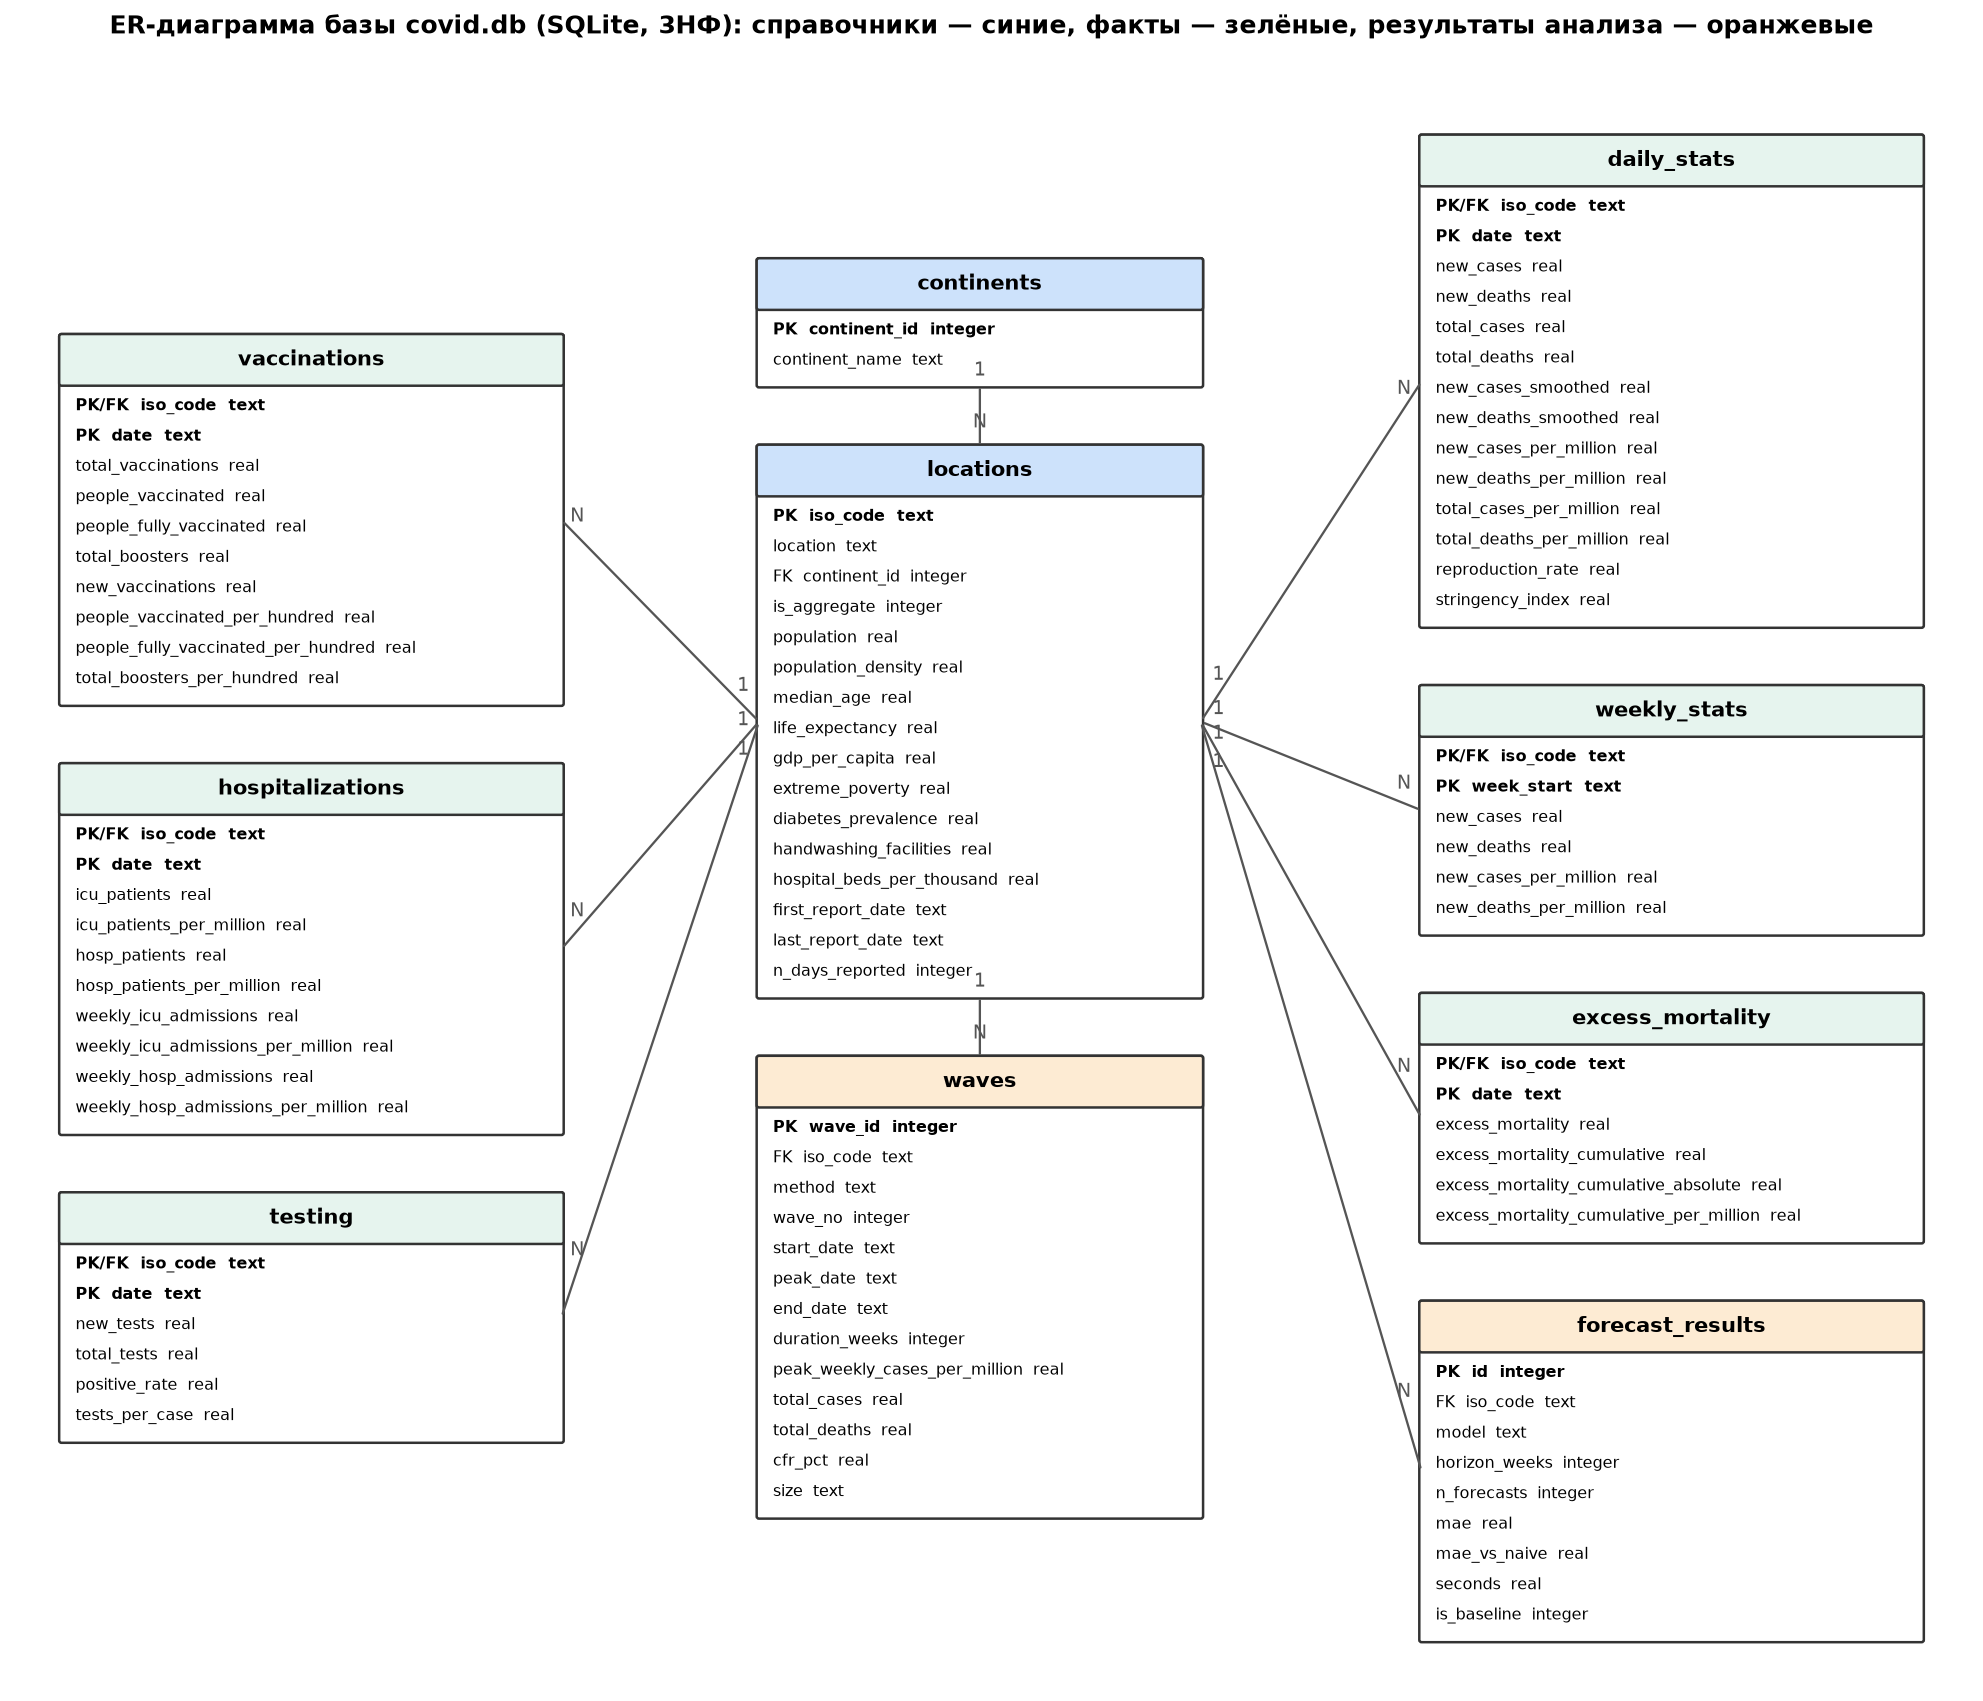

In [28]:
# ER-диаграмма базы (docs/erd.png, построена по реальной схеме SQLite)
display(Image(filename=str(config.BASE_DIR / "docs" / "erd.png"), width=1000))

In [29]:
# Таблицы и индексы базы с числом строк
from src import database

connection = database.connect()
try:
    tables_in_db = pd.read_sql_query(
        "SELECT name FROM sqlite_master WHERE type = 'table' AND name NOT LIKE 'sqlite_%' ORDER BY name", connection)
    tables_in_db["строк"] = [connection.execute(f"SELECT COUNT(*) FROM {name}").fetchone()[0] for name in tables_in_db["name"]]
    indexes = pd.read_sql_query("SELECT name, tbl_name AS таблица FROM sqlite_master WHERE type = 'index' AND name LIKE 'idx_%'", connection)
    fk_problems = connection.execute("PRAGMA foreign_key_check").fetchall()
finally:
    connection.close()
display(tables_in_db)
display(indexes)
print(f"Нарушений внешних ключей: {len(fk_problems)}")

,name,строк
0,continents,6
1,daily_stats,598223
2,excess_mortality,13748
3,forecast_results,88
4,hospitalizations,41543
5,locations,241
6,testing,104052
7,vaccinations,76748
8,waves,2245
9,weekly_stats,85555


,name,таблица
0,idx_daily_date,daily_stats
1,idx_weekly_week,weekly_stats
2,idx_waves_iso,waves
3,idx_locations_continent,locations


Нарушений внешних ключей: 0


In [30]:
# Каталог SQL-запросов: что делает каждый, какие конструкции использует, сколько строк вернул и за сколько секунд
display(table("sql_queries_summary"))

,запрос,описание,конструкции,строк,время_с
0,top15_deaths_per_million,Топ-15 стран (население ≥ 1 млн) по накопленной смертности на миллион жителей,"JOIN 3 таблиц, коррелированный подзапрос",15,0.197
1,cases_by_continent_year,"Случаи, смерти и летальность по континентам и годам (только крупные группы)","JOIN, GROUP BY, HAVING, strftime",22,0.252
2,world_monthly_change,Месячная динамика случаев в мире и изменение к предыдущему месяцу (CTE + LAG),"CTE, оконная функция LAG",82,0.001
3,rank_within_continent,Три страны с наибольшей смертностью на миллион внутри каждого континента (RANK),"CTE, JOIN, оконная функция RANK ... PARTITION BY",18,0.049
4,rolling_average_kazakhstan,"Скользящее среднее за 7 дней в SQL против готового столбца OWID (Казахстан, лето 2021)","CTE, оконная функция AVG ... ROWS BETWEEN",62,0.001
5,vaccination_vs_deaths_2022,Покрытие вакцинацией к концу 2021 г. и смертность на миллион за 2022 г. (страны > 1 млн),"2 CTE, JOIN 4 таблиц, агрегаты",155,0.032
6,waves_per_country,"Число волн по странам (≥ 1 млн жителей) и самая сильная волна каждой (ROW_NUMBER, COUNT OVER)","CTE, оконные функции ROW_NUMBER и COUNT ... OVER, JOIN",151,0.002
7,waves_by_continent,"Среднее число волн на страну, длительность и летальность волн по континентам","JOIN, GROUP BY, HAVING, COUNT DISTINCT",5,0.000
8,cfr_by_wave_year,Летальность волн по году пика: как менялась тяжесть волн по мере вакцинации,"GROUP BY, strftime, агрегаты",7,0.000
9,countries_above_world_peak,"Страны (≥ 1 млн), чей пик недельной заболеваемости втрое выше мирового (скалярный подзапрос)","JOIN, GROUP BY, HAVING со скалярным подзапросом",15,0.004


In [31]:
# Результаты четырёх запросов (из кэша main.STATE после шага 5; все 18 сохранены в outputs/tables/sql_*.csv)
from src.sql_queries import QUERIES

sql_results = main.STATE.get("sql_results") or {name: table(f"sql_{name}") for name in QUERIES}
for name, rows in [("rank_within_continent", 18), ("world_monthly_change", 10),
                   ("waves_per_country", 10), ("running_total_check", 5)]:
    print(f"\n{name}: {QUERIES[name]['описание']}")
    print(f"конструкции: {', '.join(QUERIES[name]['конструкции'])}")
    if name == "world_monthly_change":            # покажем месяцы вокруг пика Омикрона
        display(sql_results[name].set_index("month").loc["2021-10":"2022-07"].reset_index())
    else:
        display(sql_results[name].head(rows))


rank_within_continent: Три страны с наибольшей смертностью на миллион внутри каждого континента (RANK)
конструкции: CTE, JOIN, оконная функция RANK ... PARTITION BY


,continent,location,total_deaths_per_million,rank_in_continent
0,Africa,Tunisia,2427.8,1
1,Africa,South Africa,1644.7,2
2,Africa,Namibia,1422.3,3
3,Asia,Georgia,4519.6,1
4,Asia,Armenia,3049.4,2
5,Asia,Lebanon,1905.7,3
6,Europe,Bulgaria,5681.0,1
7,Europe,North Macedonia,5429.2,2
8,Europe,Bosnia and Herzegovina,5123.2,3
9,North America,United States,3631.1,1



world_monthly_change: Месячная динамика случаев в мире и изменение к предыдущему месяцу (CTE + LAG)
конструкции: CTE, оконная функция LAG


,month,cases,deaths,prev_month_cases,change_pct
0,2021-10,13501959.0,219319.0,16035345.0,-15.8
1,2021-11,15273439.0,214229.0,13501959.0,13.1
2,2021-12,23501708.0,215209.0,15273439.0,53.9
3,2022-01,91776577.0,248832.0,23501708.0,290.5
4,2022-02,58930980.0,280254.0,91776577.0,-35.8
5,2022-03,48881435.0,184599.0,58930980.0,-17.1
6,2022-04,25228136.0,84550.0,48881435.0,-48.4
7,2022-05,17070570.0,51006.0,25228136.0,-32.3
8,2022-06,16415310.0,41138.0,17070570.0,-3.8
9,2022-07,31234320.0,68260.0,16415310.0,90.3



waves_per_country: Число волн по странам (≥ 1 млн жителей) и самая сильная волна каждой (ROW_NUMBER, COUNT OVER)
конструкции: CTE, оконные функции ROW_NUMBER и COUNT ... OVER, JOIN


,location,continent,n_waves,strongest_peak_date,peak_weekly_cases_per_million,duration_weeks,cfr_pct,size
0,Cyprus,Europe,12,2022-03-21,21597.0,34,0.13,крупная
1,Denmark,Europe,11,2022-01-31,52700.7,35,0.13,крупная
2,Norway,Europe,11,2022-01-31,24907.7,32,0.18,крупная
3,Slovenia,Europe,10,2022-01-24,41287.4,24,0.30,крупная
4,Switzerland,Europe,10,2022-01-24,26081.7,33,0.09,крупная
5,Belgium,Europe,10,2022-01-24,25023.3,49,0.21,крупная
6,Czechia,Europe,10,2022-01-31,23610.7,22,0.21,крупная
7,Mauritius,Africa,10,2022-02-14,13345.8,23,0.16,крупная
8,Moldova,Europe,10,2022-01-24,8700.8,24,0.86,крупная
9,France,Europe,9,2022-01-17,33738.6,21,0.15,крупная



running_total_check: Проверка целостности: накопительная сумма new_cases (оконная SUM) против total_cases OWID (Казахстан)
конструкции: оконная функция SUM ... OVER (ORDER BY), подзапрос


,date,new_cases,total_cases,running_total,difference
0,2020-12-31,888.0,200443.0,200443.0,0.0
1,2021-12-31,522.0,1072037.0,1072037.0,0.0
2,2022-12-31,212.0,1493536.0,1493536.0,0.0
3,2023-12-31,0.0,1503205.0,1503205.0,0.0
4,2024-05-13,6.0,1504370.0,1504370.0,0.0


In [32]:
# Текст одного запроса с оконными функциями — для защиты
print(QUERIES["waves_per_country"]["sql"])


            WITH ranked AS (
                SELECT w.*,
                       ROW_NUMBER() OVER (PARTITION BY w.iso_code ORDER BY w.peak_weekly_cases_per_million DESC) AS rn,
                       COUNT(*)     OVER (PARTITION BY w.iso_code) AS n_waves
                FROM waves w
                WHERE w.method = 'peaks'
            )
            SELECT l.location, c.continent_name AS continent, r.n_waves,
                   r.peak_date AS strongest_peak_date, r.peak_weekly_cases_per_million,
                   r.duration_weeks, r.cfr_pct, r.size
            FROM ranked r
            JOIN locations  l ON l.iso_code = r.iso_code
            JOIN continents c ON c.continent_id = l.continent_id
            WHERE r.rn = 1 AND l.population >= 1000000
            ORDER BY r.n_waves DESC, r.peak_weekly_cases_per_million DESC;
        


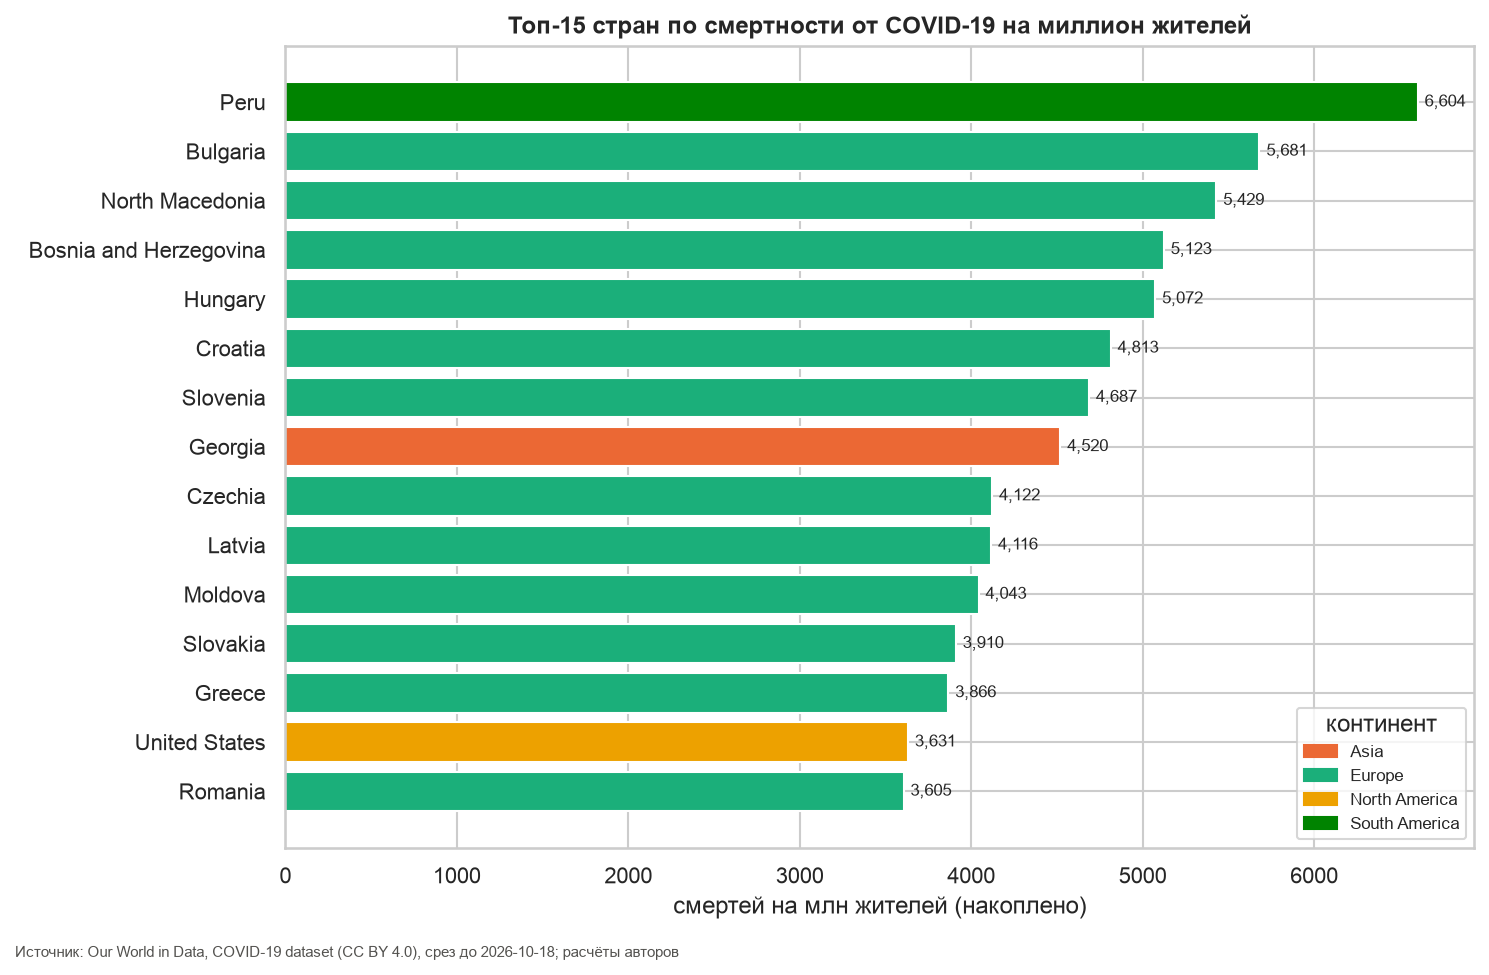

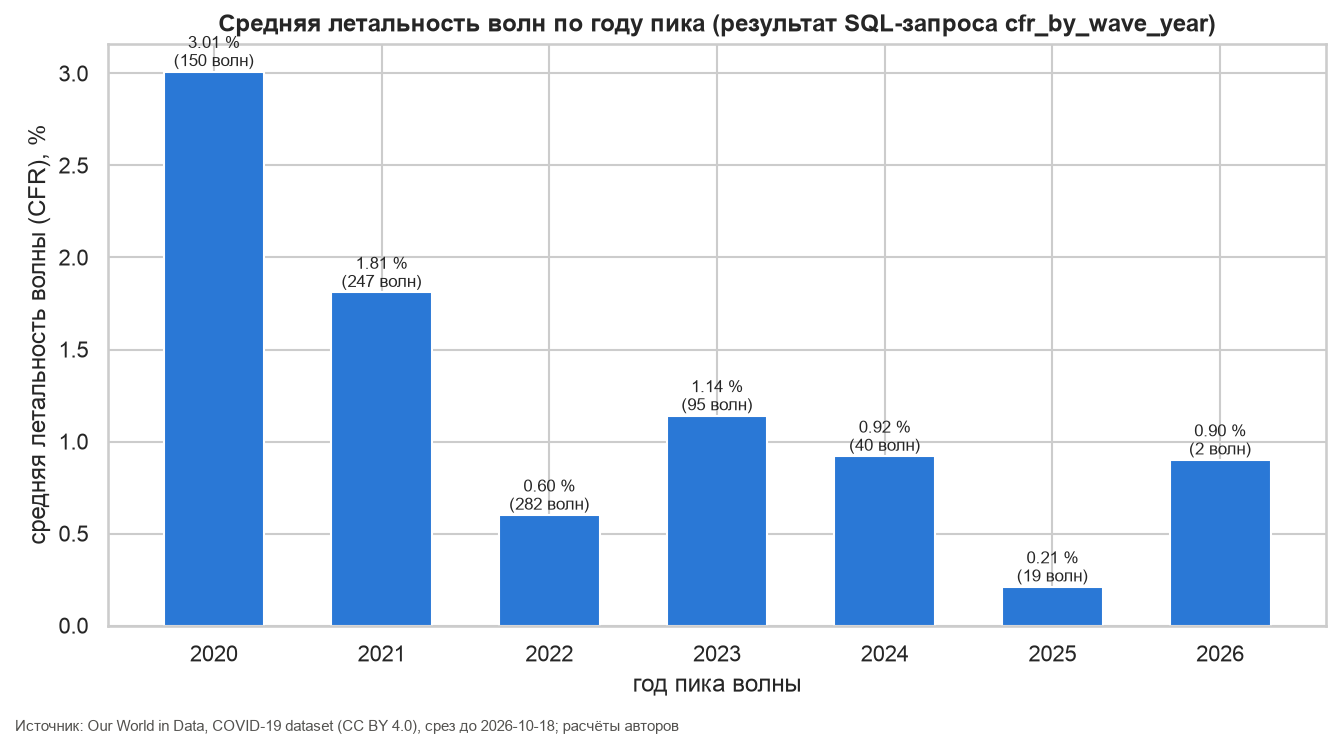

In [33]:
# Графики, построенные по результатам SQL-запросов
display(figure("top15_deaths_per_million", width=800))
display(figure("cfr_by_wave_year", width=700))

In [34]:
# Pandas vs SQL: один и тот же недельный агрегат по всем локациям двумя способами
display(table("pandas_vs_sql"))
R = results()["5_база_и_sql"]
print(f"Результаты совпадают: {R['проверка']['результаты_совпадают']}, максимальное расхождение: {R['проверка']['макс_расхождение']}")

,подход,строк,время_с_медиана
0,SQL (SQLite GROUP BY + выгрузка в pandas),85555,0.392
1,pandas (groupby в памяти),85555,0.015


Результаты совпадают: True, максимальное расхождение: 0.0


In [35]:
R = results()["5_база_и_sql"]
db = R["база"]
print(f"База {config.DB_PATH.name}: {db['размер_мб']} МБ, собрана за {db['время_сборки_с']} с; "
      f"витрина weekly_stats построена SQL-запросом за {db['weekly_из_daily_sql_с']} с")
print("Строк по таблицам: " + ", ".join(f"{name} {rows:,}" for name, rows in db["строк_по_таблицам"].items()))
print(f"Выполнено SQL-запросов: {R['запросов_выполнено']}")
for row in R["pandas_vs_sql"]:
    print(f"  {row['подход']}: {row['строк']:,} строк, медиана времени {row['время_с_медиана']} с")
print("Вывод:", R["проверка"]["вывод"])

База covid.db: 91.9 МБ, собрана за 2.739 с; витрина weekly_stats построена SQL-запросом за 0.353 с
Строк по таблицам: daily_stats 598,223, vaccinations 76,748, hospitalizations 41,543, testing 104,052, excess_mortality 13,748, weekly_stats 85,555, locations 241
Выполнено SQL-запросов: 18
  SQL (SQLite GROUP BY + выгрузка в pandas): 85,555 строк, медиана времени 0.392 с
  pandas (groupby в памяти): 85,555 строк, медиана времени 0.015 с
Вывод: pandas быстрее для расчётов в памяти; SQLite хранит данные между запусками, фильтрует их запросами и обслуживает дашборд без загрузки всего файла


**Что показывает шаг.** pandas выполняет групповой расчёт в памяти быстрее SQLite, но результат один и тот же —
роль SQL здесь другая: хранить очищенные данные между запусками, отдавать выборки фильтрами и обслуживать
дашборд без загрузки всего CSV. Результаты анализа (волны, метрики прогноза) тоже лежат в базе, поэтому
запросы вроде `waves_per_country` отвечают на содержательные вопросы прямо в SQL. Проверка накопительной суммы
(оконная `SUM`) против `total_cases` OWID дала нулевые расхождения — загруженные данные согласованы.

## 6. Корреляционный анализ и интерактивные графики

Шаг 6 (`main.step_correlation_and_interactive`, модули `src/correlation.py` и `src/visualization.py`).

Единица анализа — страна (таблица `country_summary`; страны с населением не меньше 1 млн, агрегаты исключены).
Используется коэффициент Спирмена: распределения сильно скошены, а ранговая корреляция устойчива к выбросам
и не требует линейной связи. Матрица корреляций показана тепловой картой (`corr` + `heatmap`).

Отдельно проверяется связь «вакцинация к концу 2021 г. → смертность в 2022 г.» по данным SQL-запроса
`vaccination_vs_deaths_2022`: общая корреляция, частная корреляция при контроле медианного возраста
и корреляции внутри возрастных групп стран. Это межстрановые (экологические) связи — они не доказывают
причинность.

Интерактивные графики Plotly сохраняются в `outputs/figures/*.html`: линии по странам с переключателем
показателя, анимированная карта по месяцам и диаграмма рассеяния «вакцинация — смертность». Ниже один
интерактивный график строится прямо в ноутбуке по той же недельной таблице.

In [36]:
main.step_correlation_and_interactive()

[16:11:18] ШАГ 6. Корреляции и интерактивные графики
[16:11:18] Корреляции со смертностью на млн: случаев на млн: 0.85, медианный возраст: 0.79, тестов на 1000 (полнота учёта): 0.76, ВВП на душу: 0.7, ожидаемая продолжительность жизни: 0.67, крайняя бедность, %: -0.65
[16:11:18] Вакцинация vs смертность 2022: общая 0.663, частная (возраст) -0.248; по группам: молодые (<25): 0.566; средние (25–35): 0.074; старые (35+): -0.202


[16:11:18]   график сохранён: correlation_heatmap.png
[16:11:18]   интерактивный график сохранён: interactive_weekly_cases.html


[16:11:18]   интерактивный график сохранён: interactive_map_monthly_cases.html
[16:11:18]   интерактивный график сохранён: interactive_vaccination_vs_deaths.html


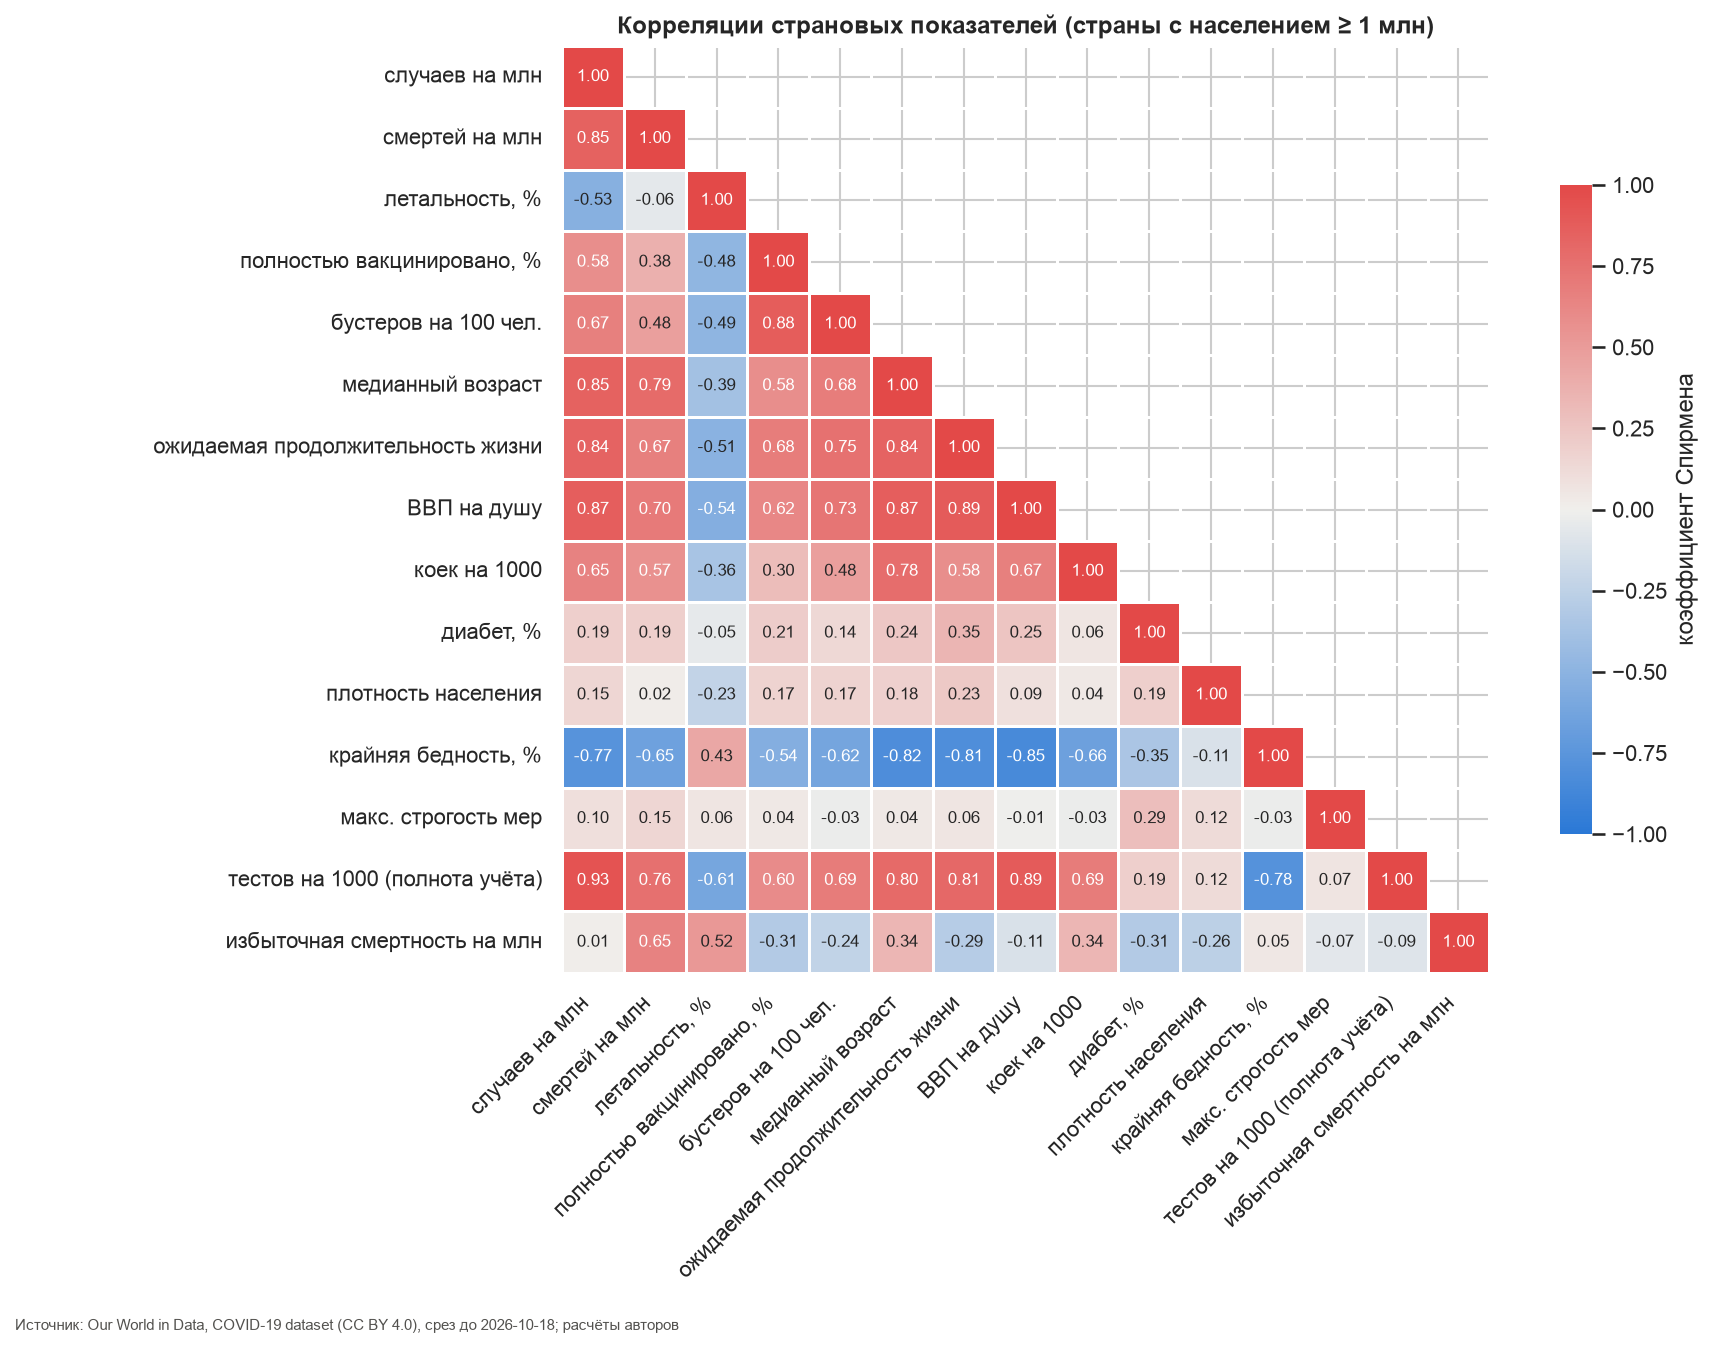

Стран в анализе: 158, метод: Spearman
Сильнейшие связи со смертностью на млн:
  случаев на млн: +0.85
  медианный возраст: +0.79
  тестов на 1000 (полнота учёта): +0.76
  ВВП на душу: +0.70
  ожидаемая продолжительность жизни: +0.67
  крайняя бедность, %: -0.65


In [37]:
# Тепловая карта корреляций Спирмена и сильнейшие связи со смертностью на миллион
display(figure("correlation_heatmap", width=850))
R = results()["6_корреляции"]
print(f"Стран в анализе: {R['стран_в_анализе']}, метод: {R['метод']}")
print("Сильнейшие связи со смертностью на млн:")
for name, value in R["сильнейшие_связи_со_смертностью_на_млн"].items():
    print(f"  {name}: {value:+.2f}")

In [38]:
# Вакцинация к концу 2021 г. и смертность в 2022 г.
print("Корреляция Спирмена «полностью вакцинировано к 31.12.2021, %» и «смертей на млн за 2022 г.»:")
print(f"  общая: {R['вакцинация_vs_смертность_2022_общая']:+.3f}")
print(f"  частная при контроле медианного возраста: {R['вакцинация_vs_смертность_2022_частная_при_контроле_возраста']:+.3f}")
print("  внутри групп стран по медианному возрасту:")
display(table("vaccination_vs_deaths_by_age_group"))
excess = R["вакцинация_vs_избыточная_смертность"]
print(f"Вакцинация и избыточная смертность на млн: Спирмен {excess['спирмен']:+.2f} ({excess['стран']} стран)")

Корреляция Спирмена «полностью вакцинировано к 31.12.2021, %» и «смертей на млн за 2022 г.»:
  общая: +0.663
  частная при контроле медианного возраста: -0.248
  внутри групп стран по медианному возрасту:


,age_group,стран,корреляция_спирмена
0,молодые (<25),61,0.566
1,средние (25–35),42,0.074
2,старые (35+),50,-0.202


Вакцинация и избыточная смертность на млн: Спирмен -0.31 (89 стран)


In [39]:
# Интерактивный график Plotly в ноутбуке: недельные случаи на миллион (наведите курсор, выделите период,
# выключите страну щелчком по легенде). Данные — недельная таблица проекта, цвета — палитра проекта.
import plotly.graph_objects as go
from src.timeseries import weekly_series
from src.visualization import PALETTE

weekly = main.get_weekly()
countries = ["Kazakhstan", "Germany", "United States", "South Africa", "India"]
fig = go.Figure()
for number, country in enumerate(countries):
    series = weekly_series(weekly, country, "new_cases_per_million").loc[config.ANALYSIS_START:config.ANALYSIS_END]
    fig.add_trace(go.Scatter(x=series.index, y=series.values, mode="lines", name=country,
                             line={"color": PALETTE[number % len(PALETTE)], "width": 1.8},
                             hovertemplate="%{x|%d.%m.%Y}: %{y:,.0f}<extra>" + country + "</extra>"))
fig.update_layout(title="COVID-19: недельные случаи на миллион жителей (интерактивный график Plotly)",
                  xaxis_title="неделя", yaxis_title="случаев на млн / нед.", template="plotly_white",
                  hovermode="x unified", legend={"orientation": "h", "y": -0.2}, height=480)
print("График интерактивный: отображается в Jupyter, VS Code и Google Colab (на GitHub в предпросмотре не виден)")
fig.show()

График интерактивный: отображается в Jupyter, VS Code и Google Colab (на GitHub в предпросмотре не виден)


**Что показывает шаг.** Со смертностью на миллион сильнее всего связаны число случаев на миллион, медианный
возраст и объём тестирования — то есть и реальный риск (пожилое население), и полнота учёта (богатые страны
больше тестируют и регистрируют). Общая корреляция между вакцинацией и смертностью 2022 г. положительна,
но при контроле возраста меняет знак — это парадокс Симпсона: старые и богатые страны одновременно лучше
привиты и теряют больше пожилых. Внутри группы «старых» стран связь отрицательная, а с избыточной смертностью —
более честной мерой потерь — вакцинация коррелирует отрицательно. Причинные выводы по таким данным делать нельзя.

## 7. Выводы, ограничения и вклад участников

In [40]:
# Сводка ключевых чисел проекта из outputs/results.json (после полного прогона шагов 1–6)
R = results()
load = R["1_данные"]["загрузка"]
clean = R["1_данные"]["после_очистки"]
methods = {row["метод"]: row for row in R["3_ряды_и_волны"]["сравнение_методов"]}
summary = pd.DataFrame(R["4_прогноз"]["сводка"])
best = {h: part.loc[part["mae_mean"].idxmin()] for h, part in summary.groupby("horizon_weeks")}
pvs = {row["подход"].split(" ")[0]: row for row in R["5_база_и_sql"]["pandas_vs_sql"]}
corr = R["6_корреляции"]

print("Ключевые числа проекта")
print(f"  данные: {load['строк']:,} строк × {load['столбцов']} столбцов, {load['размер_файла_мб']} МБ; "
      f"после очистки {clean['строк']:,} строк, {clean['локаций']} локаций")
print(f"  память: {load['память_до_оптимизации_мб']} → {load['память_после_оптимизации_мб']} МБ "
      f"(−{load['экономия_памяти_%']} %), чтение чанками за {load['время_чтения_с']} с")
print(f"  EDA: {R['2_eda']['стран_в_сводке']} стран в сводке, {R['2_eda']['выбросов_смертность_на_млн']} выбросов по смертности на млн")
print(f"  волны (страны ≥ 1 млн): порог — {methods['порог (baseline)']['волн_всего']} волн, эталонных пиков найдено "
      f"{methods['порог (baseline)']['найдено_эталонных_пиков_%']} %; пики — {methods['пики (find_peaks)']['волн_всего']} волн, "
      f"{methods['пики (find_peaks)']['найдено_эталонных_пиков_%']} %; Казахстан — {len(R['3_ряды_и_волны']['волны_казахстан'])} волн")
print(f"  прогноз: горизонт 1 нед. — лучшая {best[1]['model']} (MAE {best[1]['mae_mean']}, {best[1]['mae_vs_naive_mean']} от naive); "
      f"горизонт 4 нед. — лучшая {best[4]['model']} (MAE {best[4]['mae_mean']})")
print(f"  база: {R['5_база_и_sql']['база']['размер_мб']} МБ, daily_stats {R['5_база_и_sql']['база']['строк_по_таблицам']['daily_stats']:,} строк, "
      f"{R['5_база_и_sql']['запросов_выполнено']} SQL-запросов; pandas {pvs['pandas']['время_с_медиана']} с против SQL {pvs['SQL']['время_с_медиана']} с")
print(f"  корреляции: {corr['стран_в_анализе']} стран; вакцинация vs смертность 2022 — общая "
      f"{corr['вакцинация_vs_смертность_2022_общая']:+.3f}, при контроле возраста "
      f"{corr['вакцинация_vs_смертность_2022_частная_при_контроле_возраста']:+.3f}")

Ключевые числа проекта
  данные: 629,868 строк × 61 столбцов, 185.3 МБ; после очистки 598,223 строк, 241 локаций
  память: 326.3 → 184.6 МБ (−43.4 %), чтение чанками за 2.311 с
  EDA: 233 стран в сводке, 15 выбросов по смертности на млн
  волны (страны ≥ 1 млн): порог — 581 волн, эталонных пиков найдено 73.7 %; пики — 835 волн, 100.0 %; Казахстан — 6 волн
  прогноз: горизонт 1 нед. — лучшая linear_regression (MAE 301.908, 0.895 от naive); горизонт 4 нед. — лучшая naive (MAE 1050.388)
  база: 91.9 МБ, daily_stats 598,223 строк, 18 SQL-запросов; pandas 0.015 с против SQL 0.392 с
  корреляции: 158 стран; вакцинация vs смертность 2022 — общая +0.663, при контроле возраста -0.248


**Выводы.**

1. Набор OWID обработан с учётом памяти: чтение чанками, подбор типов и Parquet; каждое решение очистки записано
   в журнал с числом затронутых строк и обоснованием, пропуски отчётности не подменяются нулями.
2. Базовая частота анализа — неделя: это снимает эффект дня недели и делает 2020–2022 гг. сопоставимыми
   с недельной отчётностью 2023 г. и позже.
3. Волны выделены двумя методами; метод пиков (`find_peaks` на логарифме сглаженного ряда) находит все эталонные
   пики известных волн и даёт непересекающиеся волны, пороговый baseline пропускает часть пиков и склеивает волны.
   Летальность волн снижалась от первых волн к омикронным — это видно и по Казахстану, и по SQL-запросу `cfr_by_wave_year`
   (средняя CFR волн падает от 2020 к 2022 г.; после 2023 г. волн мало, и оценка шумная).
4. В прогнозе простая регрессия на лагах помогает только на неделю вперёд; на месяц вперёд в среднем ничто не обгоняет naive,
   seasonal naive не работает — у пандемии нет устойчивой годовой сезонности.
5. Очищенные данные и результаты анализа хранятся в SQLite (нормализованная схема, внешние ключи, индексы);
   18 SQL-запросов с JOIN, CTE и оконными функциями обслуживают графики и дашборд. pandas быстрее для расчётов
   в памяти, SQL — для хранения, фильтрации и подачи данных в дашборд.
6. Корреляции по странам отражают и реальный риск (возраст), и полноту учёта (тестирование); связь вакцинации
   со смертностью меняет знак при контроле возраста (парадокс Симпсона) — причинные выводы по таким данным невозможны.

**Ограничения.**

- С 2023 г. отчётность недельная и нерегулярная, к 2025 г. большинство стран не отчитываются; поэтому сравнение
  методов и прогноз ограничены окном `config.ANALYSIS_START … ANALYSIS_END` и `FORECAST_START … FORECAST_END`.
- Данные о вакцинации заканчиваются в 2023–2024 гг.; госпитализации и реанимации есть у малой доли строк.
- Летальность волн (CFR) зависит от объёма тестирования, а не только от тяжести болезни.
- Все корреляции — межстрановые (экологические) и не являются доказательством причинности.
- Замеры времени и пиковой памяти получены на одном компьютере и при повторном запуске немного меняются;
  воспроизводимые величины — строки, волны, MAE, корреляции.

**Вклад участников** (рабочее разделение; каждый участник отвечает на вопросы по любой части кода):

| Участник | Модули и материалы | Рецензент |
|---|---|---|
| Serikov Alikhan | `config.py`, `src/data_loader.py`, `src/cleaning.py`, `src/database.py` + `src/sql_queries.py` + `scripts/make_erd.py`, `src/waves.py`, `dashboard/app.py`, `main.py`, `README.md` | Mashina Veronika |
| Mashina Veronika | `src/eda.py`, `src/timeseries.py`, `src/correlation.py`, `src/forecasting.py`, `src/visualization.py`, ноутбук, письменный отчёт, презентация | Serikov Alikhan |

## 8. Дашборд Dash (запуск по желанию)

Дашборд (`dashboard/app.py`) читает данные из SQLite параметризованными SQL-запросами; фильтры — диапазон лет,
континент, страны и показатель (случаи или смерти на миллион). Графики: недельные линии с закрашенными волнами
первой выбранной страны, карта, топ-10 стран, диаграмма «вакцинация — смертность» и таблица волн.
Локально он запускается из терминала командой `python dashboard/app.py` (или пункт 8 меню `python main.py`)
и открывается по адресу http://127.0.0.1:8050. Ниже — его скриншоты, а ячейка запуска закомментирована,
чтобы выполнение ноутбука «сверху вниз» не останавливалось на работающем сервере.

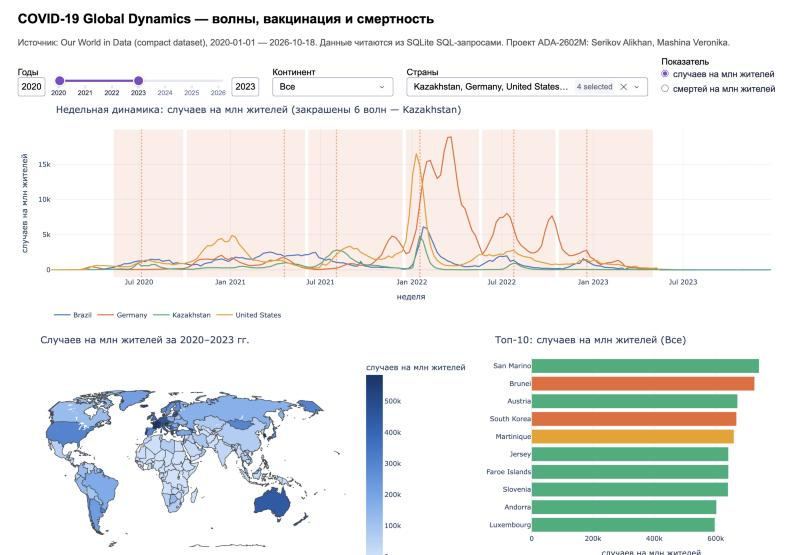

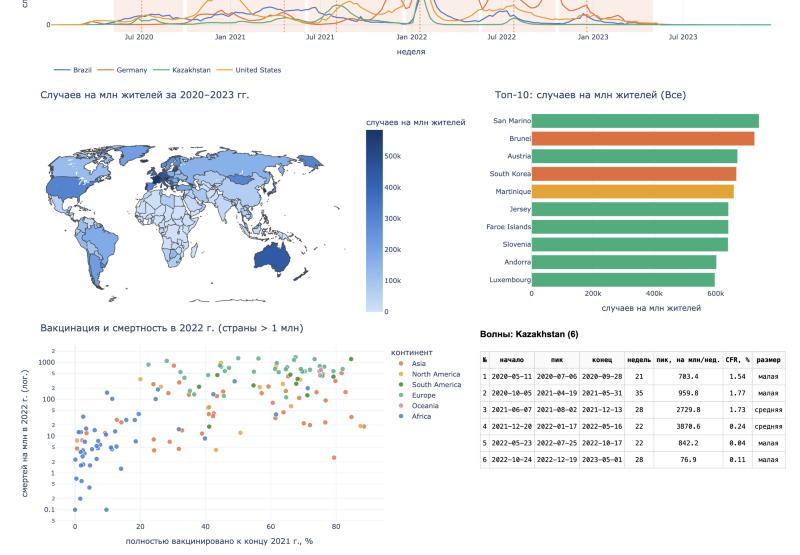

In [41]:
# Скриншоты дашборда (docs/img), сделаны при запуске python dashboard/app.py
for name in ["dashboard_top.jpg", "dashboard_bottom.jpg"]:
    display(Image(filename=str(config.BASE_DIR / "docs" / "img" / name), width=900))

In [42]:
# Запуск дашборда из ноутбука — раскомментируйте нужный вариант.

# Локально (Jupyter): сервер поднимется на порту 8050, остановка — прерывание ядра (Interrupt).
# from dashboard.app import run_dashboard
# run_dashboard(port=8050)

# В Google Colab дашборд удобнее показать прямо в ячейке:
# from dashboard.app import build_app
# app = build_app()
# app.run(jupyter_mode="inline", port=8050)